# Evaluasi Data Test

Notebook ini menilai model final dengan data test (101.129 data) dan menjawab rumusan masalah serta RQ dengan uji statistik. Model tidak dilatih ulang. Semua prediksi test sudah tersimpan di `test_sealed/` saat training di RTX 5070 Ti (notebook 06).

Data test sengaja tidak dipakai untuk memilih apa pun. Learning rate dan epoch dipilih dengan data validasi, supaya nilai test tetap jujur.

Yang dijawab di notebook ini:
- Rumusan masalah proposal: (1) performa RoBERTa vs DistilBERT, (2) efisiensi komputasi, (3) trade-off keduanya.
- RQ1: apakah jumlah layer yang dibekukan berpengaruh terhadap performa?
- RQ2: apakah parent comment berpengaruh terhadap performa?
- RQ3: strategi fusion mana yang paling baik?

Alurnya: kunci konfigurasi final (bagian 1 sampai 3), bandingkan satu per satu dengan tabel, grafik, dan uji statistik (bagian 5 sampai 11), uji pendukung (bagian 12), lalu ringkasan dan kesimpulan (bagian 13 sampai 15).

## 1. Setup

Bagian ini untuk menyiapkan library dan folder hasil test (`data/test_results_rtx5070ti/`).

In [132]:
import sys
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import chi2

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "src"))
import training as T

FULL_DIR = ROOT / "data/training_rtx5070ti/full"
RESULT_DIR = ROOT / "data/test_results_rtx5070ti"
RESULT_DIR.mkdir(exist_ok=True)
LOCK = RESULT_DIR / "final_configs.csv"
M = ["accuracy", "precision", "recall", "f1", "macro_f1"]


#### Insight
Sel ini memang tidak menampilkan output, karena hanya menyiapkan library dan folder.

## 2. Mengunci konfigurasi final

Bagian ini untuk memilih run yang akan dinilai, hanya berdasarkan hasil validasi.

- S1: learning rate terbaik tiap kombinasi model dan input diambil dari seed 42, lalu run yang sama dengan seed 43 dan 44 ikut diambil.
- S2: run dengan sebagian layer dibekukan memakai learning rate terbaik early fusion (3 seed). Run yang semua layernya dibekukan memakai learning rate dengan validasi tertinggi.

Daftarnya disimpan ke `final_configs.csv` lalu di-commit ke git sebelum data test dibuka. Kalau file itu sudah ada, isinya tidak ditimpa.

In [133]:
runs = pd.read_csv(FULL_DIR / "runs.csv")
runs["putaran"] = runs["round"].astype(str)
runs["layer"] = runs["n_train_layers"].astype(str)

s1 = runs[runs["putaran"].isin(["1", "2", "3"])]
best_lr = s1.loc[s1.groupby(["input", "model"])["val_macro_f1"].idxmax(), ["input", "model", "lr"]]
main = pd.concat([s1, runs[runs["putaran"].isin(["S43", "S44"])]]).merge(best_lr, on=["input", "model", "lr"])
main["group"] = "S1_utama"

lr_early = best_lr[best_lr["input"] == "early"].set_index("model")["lr"]
p2 = runs[runs["putaran"] == "P2"]
layer = p2[(p2["layer"] != "0") & (p2["lr"] == p2["model"].map(lr_early))]
head = p2[p2["layer"] == "0"]
head = head.loc[head.groupby("model")["val_macro_f1"].idxmax()]
p2_final = pd.concat([layer, head]).assign(group="S2_layer")

assert len(main) == 18 and main.groupby(["input", "model"])["seed"].apply(sorted).map(lambda s: s == [42, 43, 44]).all()
assert len(layer) == 9, "S2 layer 3/6 harus 3 konfigurasi x 3 seed"
final = pd.concat([main, p2_final], ignore_index=True)

cols = ["run_id", "group", "input", "model", "lr", "seed", "layer", "best_epoch", "val_macro_f1"]
if LOCK.exists():
    print("Konfigurasi sudah dikunci sebelumnya, tidak ditimpa:", LOCK)
else:
    final[cols].assign(locked_at=datetime.now().strftime("%Y-%m-%d %H:%M")).to_csv(LOCK, index=False)
    print("Konfigurasi final dikunci:", LOCK)
display(pd.read_csv(LOCK))


Konfigurasi sudah dikunci sebelumnya, tidak ditimpa: /Users/hibrizi/Project/TA/data/test_results_rtx5070ti/final_configs.csv


,run_id,group,input,model,lr,seed,layer,best_epoch,val_macro_f1,locked_at
0,R1_comment_distilbert_lr3e-05_s42,S1_utama,comment,distilbert,0.00003,42,all,2,0.767205,2026-10-16 14:27
1,R2_early_distilbert_lr1e-05_s42,S1_utama,early,distilbert,0.00001,42,all,3,0.775648,2026-10-16 14:27
2,R2_early_roberta_lr2e-05_s42,S1_utama,early,roberta,0.00002,42,all,3,0.797377,2026-10-16 14:27
3,R3_comment_roberta_lr1e-05_s42,S1_utama,comment,roberta,0.00001,42,all,3,0.783544,2026-10-16 14:27
4,R3_late_roberta_lr1e-05_s42,S1_utama,late,roberta,0.00001,42,all,3,0.791747,2026-10-16 14:27
5,R3_late_distilbert_lr1e-05_s42,S1_utama,late,distilbert,0.00001,42,all,3,0.776172,2026-10-16 14:27
6,S43_late_roberta_lr1e-05_s43,S1_utama,late,roberta,0.00001,43,all,3,0.793865,2026-10-16 14:27
7,S43_late_distilbert_lr1e-05_s43,S1_utama,late,distilbert,0.00001,43,all,3,0.776971,2026-10-16 14:27
8,S44_late_roberta_lr1e-05_s44,S1_utama,late,roberta,0.00001,44,all,3,0.791398,2026-10-16 14:27
9,S44_late_distilbert_lr1e-05_s44,S1_utama,late,distilbert,0.00001,44,all,3,0.776487,2026-10-16 14:27


#### Insight
Konfigurasi final berisi 29 run dan dikunci pada 16 Oktober pukul 14.27:

| Kelompok | Isi | Jumlah run |
|---|---|---:|
| S1 utama | 6 konfigurasi terbaik × seed 42, 43, 44 | 18 |
| S2 sebagian dibekukan | RoBERTa 6 dan 9 layer dibekukan, DistilBERT 3 layer dibekukan × 3 seed | 9 |
| S2 semua dibekukan | RoBERTa (1e-3) dan DistilBERT (1e-4), seed 42 | 2 |

Learning rate terpilih: comment saja RoBERTa 1e-5 dan DistilBERT 3e-5, early fusion RoBERTa 2e-5 dan DistilBERT 1e-5, late fusion keduanya 1e-5. File ini di-commit ke git pada 16 Oktober pukul 14.27.58 (commit `c27ab04e`), sebelum data test dibuka.

## 3. Membuka data test

Bagian ini untuk membaca prediksi test dari 29 run tadi dan memastikan semuanya memakai data dan label yang sama. Sebuah comment ditebak sarkas kalau probabilitasnya 0,5 atau lebih.

In [134]:
final = pd.read_csv(LOCK, dtype={"layer": str})
preds = {rid: pd.read_parquet(FULL_DIR / "test_sealed" / f"{rid}.parquet").set_index("raw_idx").sort_index()
         for rid in final["run_id"]}
ref = next(iter(preds.values()))
for rid, p in preds.items():
    assert p.index.equals(ref.index) and np.array_equal(p["label"].to_numpy(), ref["label"].to_numpy()), rid
y = ref["label"].to_numpy()
pred = {rid: (p["prob_sarkas"].to_numpy() >= 0.5).astype(np.int64) for rid, p in preds.items()}
print(f"{len(preds)} run | {len(y):,} data test | sarkas {y.mean():.2%}")

test = final.merge(pd.DataFrame([{"run_id": rid, **T.compute_metrics(y, preds[rid]["prob_sarkas"].to_numpy())}
                                 for rid in final["run_id"]]), on="run_id")


def mean_std(df, keys):
    g = df.groupby(keys)
    out = pd.DataFrame({m: (g[m].mean() * 100).round(2).astype(str) + " ± " + (g[m].std() * 100).round(2).astype(str) for m in M})
    out["val_macro_f1"] = (g["val_macro_f1"].mean() * 100).round(2)
    out["jumlah_seed"] = g.size()
    return out


29 run | 101,129 data test | sarkas 49.27%


#### Insight
Ke-29 run lolos pengecekan, jadi semua model dinilai dengan 101.129 data yang sama. Data test berisi 49,27% sarkas, hampir seimbang, sehingga accuracy dan macro-F1 nilainya mirip.

## 4. Persiapan grafik dan uji statistik

Bagian ini untuk menyiapkan warna grafik, data biaya komputasi, dan fungsi uji statistik.

Setiap perbandingan di bagian 5 sampai 11 polanya sama: tabel, grafik batang, lalu uji statistik. Ujinya ada dua jenis:
- Membandingkan 2 hal, misalnya RoBERTa dan DistilBERT. H1: A lebih tinggi dari B. H0: A tidak lebih tinggi dari B. Ujinya paired t-test satu arah, ditambah Wilcoxon kalau pasangannya lebih dari 3. Dengan 3 pasangan saja, p Wilcoxon paling kecil 0,125, jadi tidak mungkin signifikan.
- Membandingkan 3 hal atau lebih, misalnya comment saja, early fusion, dan late fusion. Ujinya Friedman. H0: semuanya sama. H1: minimal ada satu yang berbeda.

Yang dibandingkan adalah macro-F1 data test per seed. Pasangannya selalu pada seed yang sama.

Supaya tidak hanya melihat nilai p, setiap uji juga menampilkan:
- besar efek: selisih A - B dengan rentang 95% (CI 95%) untuk uji 2 hal, atau Kendall's W (0 sampai 1) untuk Friedman,
- p Shapiro: cek apakah selisih A - B kira-kira normal, syarat paired t-test. Hanya dihitung kalau pasangannya lebih dari 3,
- p Holm: nilai p yang dikoreksi karena ujinya banyak. Keputusan akhir di bagian 13 memakai p Holm.

Taraf signifikansi 0,05. Hasil uji tidak membuktikan jawaban secara mutlak, hanya menunjukkan apakah ada bukti statistik yang cukup.

In [5]:
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, shapiro, t as t_dist, ttest_rel, wilcoxon

FIG_DIR = ROOT / "data/figures_paper"
FIG_DIR.mkdir(exist_ok=True)
WARNA = {"roberta": "#2a78d6", "distilbert": "#eb6834"}                       # biru dan oranye, aman untuk buta warna
WARNA_INPUT = {"comment": "#9aa7b4", "early": "#1baf7a", "late": "#7a52c7"}
NAMA = {"roberta": "RoBERTa", "distilbert": "DistilBERT"}
INPUT = {"comment": "Comment saja", "early": "Early fusion", "late": "Late fusion"}
TOTAL_LAYER = {"roberta": 12, "distilbert": 6}
SEEDS = [42, 43, 44]
BIAYA = {"train_min_per_epoch": "Waktu training (menit/epoch)", "latency_bs1_ms": "Latensi batch 1 (ms)",
         "latency_bs32_ms": "Latensi batch 32 (ms per data)", "peak_mem_gb": "Memori GPU (GB)"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True, "legend.frameon": False,
})

# Skor test dan biaya komputasi per run final
biaya_run = runs.set_index("run_id")[list(BIAYA) + ["params_total_m"]]
main_t = test[test["group"] == "S1_utama"].join(biaya_run, on="run_id")
beku = pd.concat([test[test["group"] == "S2_layer"],
                  main_t[main_t["input"] == "early"].assign(layer=lambda d: d["model"].map(TOTAL_LAYER).astype(str))])
beku["dibekukan"] = beku["model"].map(TOTAL_LAYER) - beku["layer"].astype(int)
beku = beku.drop(columns=list(BIAYA) + ["params_total_m"], errors="ignore").join(biaya_run, on="run_id")

koma = lambda v, d=2: f"{v:.{d}f}".replace(".", ",")


def simpan(fig, nama):
    fig.savefig(FIG_DIR / f"{nama}.png", dpi=300, bbox_inches="tight")


def label_batang(ax, batang, nilai, d=2, size=9, rot=0):
    for b, v in zip(batang, nilai):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + (0.08 if rot else 0.05), koma(v, d),
                ha="center", va="bottom", fontsize=size, rotation=rot)


def rapikan(ax, ylim=None, ylabel=""):
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: koma(v, 0) if float(v).is_integer() else koma(v, 1)))


SEMUA_UJI = {}                       # kunci (bagian, H1), jadi menjalankan ulang sel tidak membuat uji ganda


def uji_dua(bagian, h1, a, b, utama=False):
    """H1: A lebih besar dari B. A dan B berpasangan (seed, model, atau input yang sama)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    d = a - b
    se = d.std(ddof=1) / np.sqrt(len(d))
    lebar = t_dist.ppf(0.975, len(d) - 1) * se
    hasil = {"bagian": bagian, "H1": h1, "uji": "paired t-test" + (" + Wilcoxon" if len(d) > 3 else ""),
             "pasangan": len(d), "A menang": f"{(d > 0).sum()}/{len(d)}", "rata-rata A": a.mean(), "rata-rata B": b.mean(),
             "selisih": d.mean(), "CI 95% bawah": d.mean() - lebar, "CI 95% atas": d.mean() + lebar,
             "p Shapiro": shapiro(d).pvalue if len(d) > 3 else np.nan,
             "p t-test": ttest_rel(a, b, alternative="greater").pvalue,
             "p Wilcoxon": wilcoxon(a, b, alternative="greater").pvalue if len(d) > 3 else np.nan, "utama": utama}
    hasil["keputusan"] = "tolak H0" if hasil["p t-test"] < 0.05 else "gagal tolak H0"
    SEMUA_UJI[(bagian, h1)] = hasil
    return hasil


def uji_friedman(bagian, h1, tabel, utama=False):
    """Friedman test: baris = blok (pasangan yang sama), kolom = perlakuan yang dibandingkan."""
    stat, p = friedmanchisquare(*[tabel[c] for c in tabel.columns])
    kendall_w = stat / (len(tabel) * (tabel.shape[1] - 1))
    hasil = {"bagian": bagian, "H1": h1, "uji": "Friedman", "pasangan": len(tabel), "statistik": stat, "Kendall W": kendall_w,
             "p Friedman": p, "keputusan": "tolak H0" if p < 0.05 else "gagal tolak H0", "utama": utama}
    SEMUA_UJI[(bagian, h1)] = hasil
    return hasil


def tampil_uji(daftar):
    df = pd.DataFrame(daftar).drop(columns=["bagian", "utama"])
    if "CI 95% bawah" in df:
        df.insert(df.columns.get_loc("CI 95% bawah"), "CI 95% selisih",
                  [f"{koma(lo)} sampai {koma(hi)}" for lo, hi in zip(df["CI 95% bawah"], df["CI 95% atas"])])
        df = df.drop(columns=["CI 95% bawah", "CI 95% atas"])
    fmt_p = lambda p: "-" if pd.isna(p) else ("< 0,001" if p < 0.001 else koma(p, 3))
    for c in df.columns:
        if c.startswith("p "):
            df[c] = df[c].map(fmt_p)
        elif c in ["rata-rata A", "rata-rata B", "selisih", "statistik", "Kendall W"]:
            df[c] = df[c].map(lambda v: "-" if pd.isna(v) else koma(v))
    df = df.rename(columns={"keputusan": "keputusan (sebelum Holm)"})
    df.index = range(1, len(df) + 1)
    with pd.option_context("display.max_colwidth", 70):
        display(df)


def nomor(df):
    df = df.reset_index()
    df.index = range(1, len(df) + 1)
    return df


print(f"{len(main_t)} run utama, {len(beku)} run untuk analisis layer dibekukan")

18 run utama, 17 run untuk analisis layer dibekukan


## 5. Hasil semua konfigurasi utama

Bagian ini untuk melihat kelima metrik dari 6 konfigurasi utama (2 model × 3 input), rata-rata 3 seed. Kolom `val_macro_f1` dipakai untuk membandingkan nilai test dengan validasi.

,input,model,accuracy,precision,recall,f1,macro_f1,val_macro_f1,jumlah_seed
1,comment,distilbert,76.88 ± 0.08,76.94 ± 0.65,75.8 ± 1.17,76.36 ± 0.29,76.87 ± 0.08,76.60,3
2,comment,roberta,78.53 ± 0.07,78.33 ± 0.36,77.99 ± 0.46,78.16 ± 0.05,78.52 ± 0.06,78.34,3
3,early,distilbert,77.58 ± 0.06,78.14 ± 1.11,75.7 ± 2.03,76.88 ± 0.53,77.55 ± 0.09,77.50,3
4,early,roberta,79.63 ± 0.05,79.37 ± 1.31,79.32 ± 2.22,79.32 ± 0.48,79.62 ± 0.06,79.69,3
5,late,distilbert,77.6 ± 0.02,77.62 ± 0.07,76.61 ± 0.07,77.12 ± 0.02,77.59 ± 0.02,77.65,3
6,late,roberta,79.3 ± 0.02,78.82 ± 0.21,79.29 ± 0.39,79.06 ± 0.09,79.3 ± 0.02,79.23,3


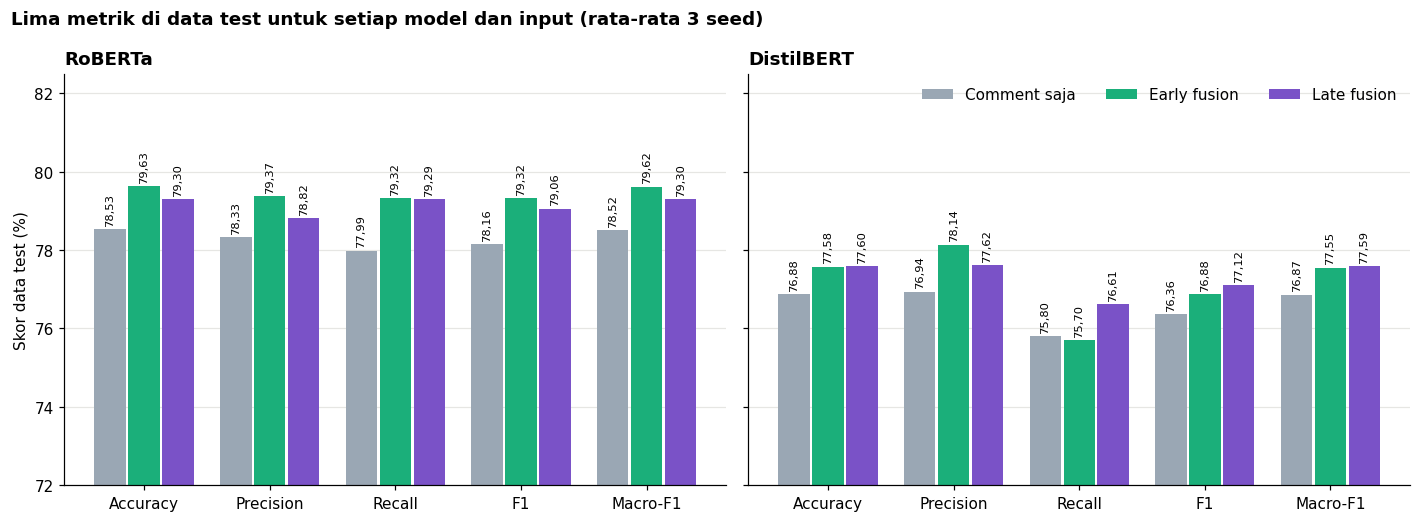

In [7]:
summary = mean_std(main_t, ["input", "model"])
display(nomor(summary))

lima = main_t.groupby(["model", "input"])[M].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
x, w = np.arange(len(M)), 0.27
for ax, m in zip(axes, NAMA):
    for j, i in enumerate(INPUT):
        v = lima.loc[(m, i)].values
        label_batang(ax, ax.bar(x + (j - 1) * w, v, w - 0.02, color=WARNA_INPUT[i], label=INPUT[i]), v, size=7.5, rot=90)
    ax.set_xticks(x, ["Accuracy", "Precision", "Recall", "F1", "Macro-F1"])
    rapikan(ax, (72, 82.5), "Skor data test (%)" if m == "roberta" else "")
    ax.set_title(NAMA[m], loc="left", fontweight="bold")
axes[1].legend(ncol=3, loc="upper right")
fig.suptitle("Lima metrik di data test untuk setiap model dan input (rata-rata 3 seed)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan(fig, "fig_lima_metrik")
plt.show()

#### Insight
Hasil terbaik di kelima metrik adalah early fusion RoBERTa: accuracy 79,63 ± 0,05, precision 79,37 ± 1,31, recall 79,32 ± 2,22, F1 79,32 ± 0,48, dan macro-F1 79,62 ± 0,06. Untuk metrik dan input yang sama, batang RoBERTa selalu lebih tinggi dari DistilBERT.

Early fusion DistilBERT punya precision tinggi (78,14) tetapi recall rendah (75,70). Artinya model ini lebih hati-hati menebak sarkas, jadi lebih banyak sarkas yang terlewat.

Hasilnya stabil. Simpangan baku accuracy dan macro-F1 paling besar 0,09, dan selisih macro-F1 test dengan validasi hanya -0,07 sampai +0,26 poin.

## 6. Perbandingan model: RoBERTa vs DistilBERT

Bagian ini untuk menjawab rumusan masalah pertama, yaitu model mana yang lebih baik.

- H0: macro-F1 RoBERTa tidak lebih tinggi dari DistilBERT.
- H1: macro-F1 RoBERTa lebih tinggi dari DistilBERT.

Diuji per input (3 pasangan seed) dan gabungan ketiga input (9 pasangan).

model,input,roberta,distilbert,selisih
1,comment,78.52,76.87,1.65
2,early,79.62,77.55,2.07
3,late,79.30,77.59,1.71


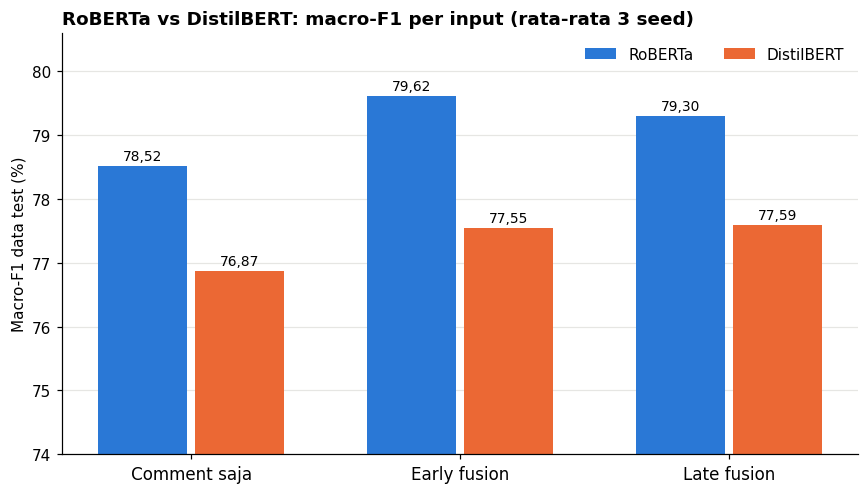

,H1,uji,pasangan,A menang,rata-rata A,rata-rata B,selisih,CI 95% selisih,p Shapiro,p t-test,p Wilcoxon,keputusan (sebelum Holm)
1,RoBERTa > DistilBERT (comment saja),paired t-test,3,3/3,"78,52","76,87","1,65","1,30 sampai 2,00",-,"0,001",-,tolak H0
2,RoBERTa > DistilBERT (early fusion),paired t-test,3,3/3,"79,62","77,55","2,07","1,92 sampai 2,22",-,"< 0,001",-,tolak H0
3,RoBERTa > DistilBERT (late fusion),paired t-test,3,3/3,"79,30","77,59","1,71","1,61 sampai 1,82",-,"< 0,001",-,tolak H0
4,RoBERTa > DistilBERT (gabungan 3 input),paired t-test + Wilcoxon,9,9/9,"79,15","77,34","1,81","1,65 sampai 1,97","0,321","< 0,001","0,002",tolak H0


In [8]:
f1_model = main_t.pivot_table(index=["input", "seed"], columns="model", values="macro_f1") * 100
tabel = f1_model.groupby(level="input").mean().reindex(list(INPUT))[["roberta", "distilbert"]]
tabel["selisih"] = tabel["roberta"] - tabel["distilbert"]
display(nomor(tabel.round(2)))

fig, ax = plt.subplots(figsize=(8, 4.6))
x, w = np.arange(3), 0.36
for j, m in enumerate(NAMA):
    v = tabel[m].values
    label_batang(ax, ax.bar(x + (j - 0.5) * w, v, w - 0.03, color=WARNA[m], label=NAMA[m]), v)
ax.set_xticks(x, list(INPUT.values()), fontsize=11)
rapikan(ax, (74, 80.6), "Macro-F1 data test (%)")
ax.set_title("RoBERTa vs DistilBERT: macro-F1 per input (rata-rata 3 seed)", loc="left", fontweight="bold")
ax.legend(ncol=2, loc="upper right")
fig.tight_layout()
simpan(fig, "fig_perbandingan_model")
plt.show()

uji_model = [uji_dua("Model", f"RoBERTa > DistilBERT ({INPUT[i].lower()})", f1_model.loc[i, "roberta"], f1_model.loc[i, "distilbert"])
             for i in INPUT]
uji_model.append(uji_dua("Model", "RoBERTa > DistilBERT (gabungan 3 input)", f1_model["roberta"], f1_model["distilbert"], utama=True))
tampil_uji(uji_model)

#### Insight
RoBERTa lebih tinggi di ketiga input: +1,65 poin (comment saja), +2,07 (early fusion), dan +1,71 (late fusion). Gabungannya +1,81 poin (CI 95% 1,65 sampai 1,97), menang 9 dari 9 pasangan, dengan p t-test < 0,001 dan p Wilcoxon 0,002. H0 ditolak, dan tetap ditolak setelah koreksi Holm. Asumsi normal juga terpenuhi (p Shapiro 0,321).

Jawaban rumusan masalah pertama: ada bukti statistik bahwa RoBERTa lebih baik dari DistilBERT, tetapi selisihnya kecil, sekitar 2 poin.

## 7. Perbandingan input: comment saja vs early fusion vs late fusion (RQ2 dan RQ3)

Bagian ini untuk menjawab RQ2 (apakah parent berpengaruh) dan RQ3 (fusion mana yang terbaik). Comment saja tidak memakai parent, sedangkan early dan late fusion memakai comment + parent dengan cara penggabungan berbeda.

Ketiga input diuji dulu dengan Friedman (blok: model × seed).
- H0: ketiga input sama. H1: minimal ada satu yang berbeda.

Lalu tiap pasangan diuji satu arah:
- RQ2: early fusion > comment saja, dan late fusion > comment saja.
- RQ3: early fusion > late fusion.

input,model,comment,early,late
1,roberta,78.52,79.62,79.30
2,distilbert,76.87,77.55,77.59


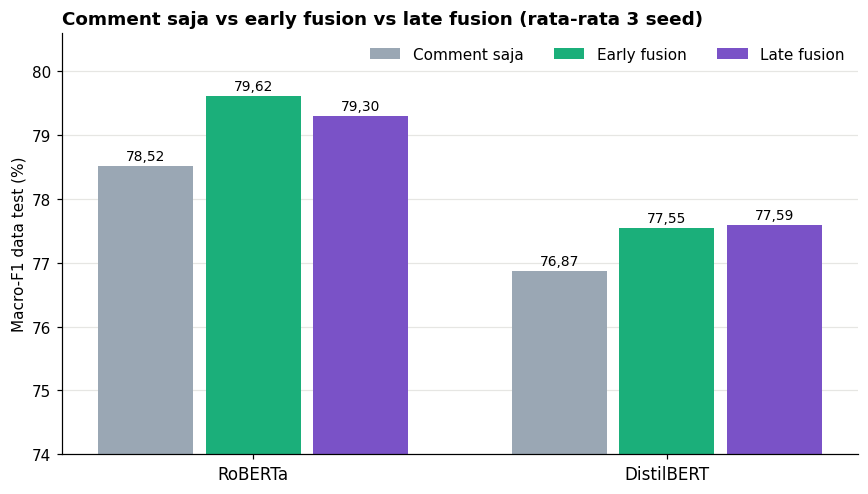

,H1,uji,pasangan,statistik,Kendall W,p Friedman,keputusan (sebelum Holm)
1,"Minimal satu input berbeda (comment, early, late)",Friedman,6,"9,33","0,78","0,009",tolak H0


,H1,uji,pasangan,A menang,rata-rata A,rata-rata B,selisih,CI 95% selisih,p Shapiro,p t-test,p Wilcoxon,keputusan (sebelum Holm)
1,RoBERTa: early fusion > comment saja,paired t-test,3,3/3,"79,62","78,52","1,10","0,83 sampai 1,37",-,"0,002",-,tolak H0
2,DistilBERT: early fusion > comment saja,paired t-test,3,3/3,"77,55","76,87","0,69","0,65 sampai 0,72",-,"< 0,001",-,tolak H0
3,Early fusion > comment saja (gabungan 2 model),paired t-test + Wilcoxon,6,6/6,"78,59","77,69","0,89","0,64 sampai 1,14","0,115","< 0,001","0,016",tolak H0
4,RoBERTa: late fusion > comment saja,paired t-test,3,3/3,"79,30","78,52","0,78","0,60 sampai 0,96",-,"0,001",-,tolak H0
5,DistilBERT: late fusion > comment saja,paired t-test,3,3/3,"77,59","76,87","0,72","0,53 sampai 0,92",-,"0,002",-,tolak H0
6,Late fusion > comment saja (gabungan 2 model),paired t-test + Wilcoxon,6,6/6,"78,44","77,69","0,75","0,67 sampai 0,83","0,241","< 0,001","0,016",tolak H0
7,RoBERTa: early fusion > late fusion,paired t-test,3,3/3,"79,62","79,30","0,32","0,15 sampai 0,49",-,"0,008",-,tolak H0
8,DistilBERT: early fusion > late fusion,paired t-test,3,1/3,"77,55","77,59","-0,04","-0,26 sampai 0,19",-,"0,725",-,gagal tolak H0
9,Early fusion > late fusion (gabungan 2 model),paired t-test + Wilcoxon,6,4/6,"78,59","78,44","0,14","-0,08 sampai 0,36","0,550","0,079","0,109",gagal tolak H0


In [9]:
f1_input = main_t.pivot_table(index=["model", "seed"], columns="input", values="macro_f1")[list(INPUT)] * 100
tabel = f1_input.groupby(level="model").mean().reindex(list(NAMA))
display(nomor(tabel.round(2)))

fig, ax = plt.subplots(figsize=(8, 4.6))
x, w = np.arange(2), 0.26
for j, i in enumerate(INPUT):
    v = tabel[i].values
    label_batang(ax, ax.bar(x + (j - 1) * w, v, w - 0.03, color=WARNA_INPUT[i], label=INPUT[i]), v)
ax.set_xticks(x, list(NAMA.values()), fontsize=11)
rapikan(ax, (74, 80.6), "Macro-F1 data test (%)")
ax.set_title("Comment saja vs early fusion vs late fusion (rata-rata 3 seed)", loc="left", fontweight="bold")
ax.legend(ncol=3, loc="upper right")
fig.tight_layout()
simpan(fig, "fig_perbandingan_input")
plt.show()

tampil_uji([uji_friedman("RQ2 dan RQ3", "Minimal satu input berbeda (comment, early, late)", f1_input, utama=True)])
uji_input = []
for inp in ["early", "late"]:
    for m in NAMA:
        uji_input.append(uji_dua("RQ2", f"{NAMA[m]}: {INPUT[inp].lower()} > comment saja", f1_input.loc[m, inp], f1_input.loc[m, "comment"]))
    uji_input.append(uji_dua("RQ2", f"{INPUT[inp]} > comment saja (gabungan 2 model)", f1_input[inp], f1_input["comment"], utama=True))
for m in NAMA:
    uji_input.append(uji_dua("RQ3", f"{NAMA[m]}: early fusion > late fusion", f1_input.loc[m, "early"], f1_input.loc[m, "late"], utama=True))
uji_input.append(uji_dua("RQ3", "Early fusion > late fusion (gabungan 2 model)", f1_input["early"], f1_input["late"], utama=True))
tampil_uji(uji_input)

#### Insight
Friedman: p 0,009 dan Kendall's W 0,78, jadi H0 ditolak. Ada bukti statistik bahwa jenis input berpengaruh, dan urutannya cukup konsisten di semua blok.

RQ2: parent menaikkan macro-F1 di semua kombinasi. Early fusion +1,10 poin pada RoBERTa dan +0,69 pada DistilBERT, late fusion +0,78 dan +0,72. Semua p di bawah 0,05, juga setelah koreksi Holm. Gabungan kedua model menang 6 dari 6 pasangan (p Wilcoxon 0,016). Jadi ada bukti statistik bahwa parent comment berpengaruh.

RQ3: pada RoBERTa, early fusion lebih tinggi 0,32 poin dari late fusion (p Holm 0,023). Pada DistilBERT keduanya hampir sama (-0,04 poin, p 0,725). Kalau digabung, belum ada bukti yang cukup (p Holm 0,158). Karena late fusion jauh lebih mahal (bagian 11), early fusion adalah pilihan terbaik.

### 7.1 Kapan parent paling membantu

Bagian ini untuk melihat jenis comment apa yang paling terbantu parent. Comment saja dibandingkan dengan early fusion pada beberapa kelompok data test:
- Model ragu: model comment saja RoBERTa ragu (rata-rata probabilitas 3 seed 0,4 sampai 0,6). Model yakin: di luar itu.
- Comment kembar: kalimat comment sama persis (huruf kecil, tanpa tanda baca), tetapi labelnya beda.
- 1-3 kata, 4-10 kata, >10 kata: panjang comment.
- Kontras sentimen: parent negatif dan comment positif (VADER). Sama-sama netral: keduanya netral.
- Semua data: seluruh data test, sebagai patokan.

Tiap kelompok diuji dengan McNemar per seed. Kolom `signifikan_3_seed` bernilai "ya" kalau p di bawah 0,05 di ketiga seed.

In [10]:
from sklearn.metrics import f1_score
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

teks = pd.read_parquet(ROOT / "data/split_full/test.parquet").set_index("raw_idx").sort_index()
assert teks.index.equals(ref.index)
kunci = (teks["comment_clean"].str.lower().str.replace(r"[^\w\s]", " ", regex=True)
         .str.replace(r"\s+", " ", regex=True).str.strip())
kunci = kunci.where(kunci != "", teks["comment_clean"]).to_numpy()
rid_cp = main_t.set_index(["input", "model", "seed"])["run_id"]
P = {(i, m, s): pred[rid_cp[(i, m, s)]] for i in ["comment", "early"] for m in NAMA for s in SEEDS}
prob_c = np.mean([preds[rid_cp[("comment", "roberta", s)]]["prob_sarkas"].to_numpy() for s in SEEDS], axis=0)

grp = pd.DataFrame({"k": kunci, "y": y}).groupby("k")["y"].agg(["size", "nunique"])
kembar = np.isin(kunci, grp[(grp["size"] >= 2) & (grp["nunique"] == 2)].index)
n_kata = pd.Series(kunci).str.split().str.len().to_numpy()
vader = SentimentIntensityAnalyzer()
kategori = lambda s: np.where(s < -0.05, "neg", np.where(s > 0.05, "pos", "net"))
s_par = kategori(np.array([vader.polarity_scores(t)["compound"] for t in teks["parent_comment"]]))
s_com = kategori(np.array([vader.polarity_scores(t)["compound"] for t in teks["comment"]]))
KELOMPOK = {
    "Model ragu": (prob_c >= 0.4) & (prob_c <= 0.6),
    "Comment kembar": kembar,
    "1-3 kata": n_kata <= 3,
    "4-10 kata": (n_kata >= 4) & (n_kata <= 10),
    "Sama-sama netral": (s_par == "net") & (s_com == "net"),
    "Semua data": np.ones(len(y), bool),
    "Kontras sentimen": (s_par == "neg") & (s_com == "pos"),
    ">10 kata": n_kata > 10,
    "Model yakin": (prob_c < 0.4) | (prob_c > 0.6),
}
baris = []
for nama, mask in KELOMPOK.items():
    for m in NAMA:
        for s in SEEDS:
            pc, pe, yy = P[("comment", m, s)][mask], P[("early", m, s)][mask], y[mask]
            fix, brk = int(((pe == yy) & (pc != yy)).sum()), int(((pe != yy) & (pc == yy)).sum())
            baris.append({"kelompok": nama, "model": m, "seed": s, "n": int(mask.sum()),
                          "macro_f1_comment": f1_score(yy, pc, average="macro") * 100,
                          "macro_f1_early": f1_score(yy, pe, average="macro") * 100,
                          "diperbaiki_parent": fix, "dirusak_parent": brk,
                          "p_mcnemar": chi2.sf((abs(fix - brk) - 1) ** 2 / max(fix + brk, 1), 1)})
parent_raw = pd.DataFrame(baris)
parent_raw["kenaikan"] = parent_raw["macro_f1_early"] - parent_raw["macro_f1_comment"]
g = parent_raw.groupby(["kelompok", "model"], sort=False)
parent_ringkas = g[["n", "macro_f1_comment", "macro_f1_early", "kenaikan", "diperbaiki_parent", "dirusak_parent"]].mean()
parent_ringkas["p_terbesar"] = g["p_mcnemar"].max()
parent_ringkas["signifikan_3_seed"] = np.where(parent_ringkas["p_terbesar"] < 0.05, "ya", "tidak")
display(nomor(parent_ringkas.round({"macro_f1_comment": 2, "macro_f1_early": 2, "kenaikan": 2, "diperbaiki_parent": 0,
                                    "dirusak_parent": 0, "p_terbesar": 4})))
print(f"Comment kembar: {grp[(grp['size'] >= 2) & (grp['nunique'] == 2)].shape[0]:,} kalimat, {kembar.sum():,} baris")

,kelompok,model,n,macro_f1_comment,macro_f1_early,kenaikan,diperbaiki_parent,dirusak_parent,p_terbesar,signifikan_3_seed
1,Model ragu,roberta,10737.0,52.08,60.26,8.18,2848.0,1957.0,0.0000,ya
2,Model ragu,distilbert,10737.0,53.50,55.95,2.44,1729.0,1450.0,0.0000,ya
3,Comment kembar,roberta,5886.0,70.13,72.86,2.73,346.0,222.0,0.0000,ya
4,Comment kembar,distilbert,5886.0,68.31,69.82,1.51,328.0,262.0,0.1042,tidak
5,1-3 kata,roberta,14566.0,72.46,75.06,2.59,1064.0,820.0,0.0000,ya
6,1-3 kata,distilbert,14566.0,71.11,72.04,0.93,921.0,845.0,0.0872,tidak
7,4-10 kata,roberta,44696.0,76.08,77.38,1.29,3102.0,2525.0,0.0000,ya
8,4-10 kata,distilbert,44696.0,74.55,75.59,1.04,3105.0,2651.0,0.0000,ya
9,Sama-sama netral,roberta,13866.0,74.37,75.61,1.24,947.0,780.0,0.0006,ya
10,Sama-sama netral,distilbert,13866.0,73.02,73.70,0.69,935.0,812.0,0.0265,ya


Comment kembar: 593 kalimat, 5,886 baris


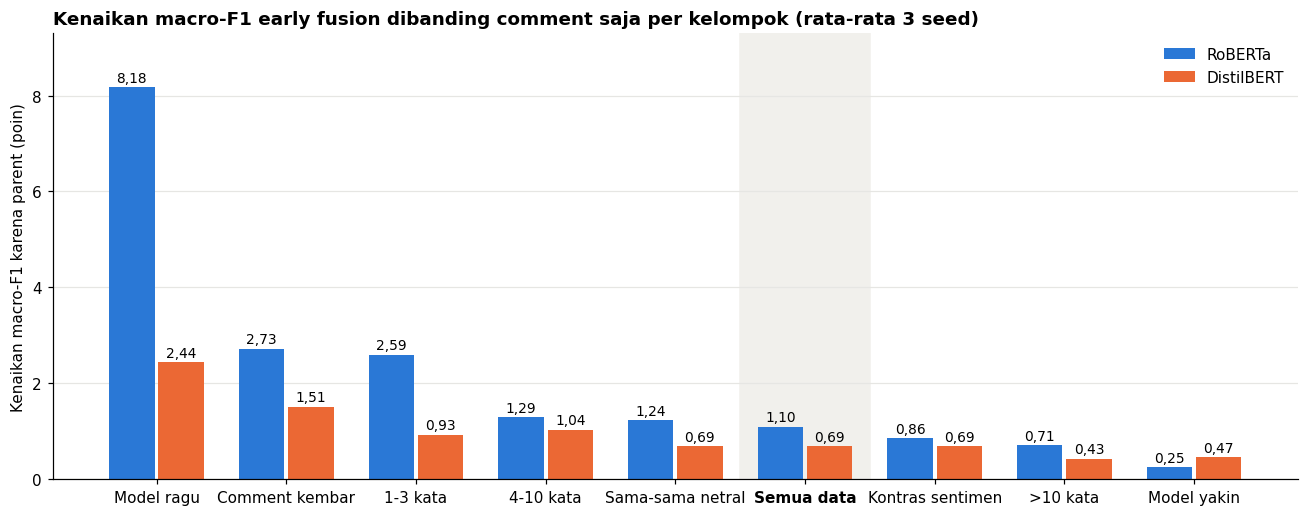

In [11]:
naik = parent_ringkas["kenaikan"].unstack("model").reindex(list(KELOMPOK))
fig, ax = plt.subplots(figsize=(12, 4.8))
posisi, lebar = np.arange(len(naik)), 0.38
pos_rata = list(naik.index).index("Semua data")
ax.axvspan(pos_rata - 0.5, pos_rata + 0.5, color="#f1f0ec", zorder=0)
for j, m in enumerate(NAMA):
    label_batang(ax, ax.bar(posisi + (j - 0.5) * lebar, naik[m], lebar - 0.03, color=WARNA[m], label=NAMA[m]), naik[m], d=2)
ax.set_xticks(posisi, naik.index)
ax.get_xticklabels()[pos_rata].set_fontweight("bold")
rapikan(ax, (0, 9.3), "Kenaikan macro-F1 karena parent (poin)")
ax.set_title("Kenaikan macro-F1 early fusion dibanding comment saja per kelompok (rata-rata 3 seed)", loc="left", fontweight="bold")
ax.legend(loc="upper right")
fig.tight_layout()
simpan(fig, "fig_manfaat_parent")
plt.show()

#### Insight
Parent paling membantu saat model ragu: +8,18 poin pada RoBERTa (52,08 menjadi 60,26) dan +2,44 pada DistilBERT. Berikutnya comment kembar (+2,73 dan +1,51) dan comment 1-3 kata (+2,59 dan +0,93). Saat model sudah yakin, kenaikannya hanya +0,25 dan +0,47.

Kelompok kontras sentimen (+0,86 pada RoBERTa) malah di bawah sama-sama netral (+1,24), jadi model tidak hanya mengandalkan pola "parent negatif, comment positif". Parent juga bisa salah arah. Pada RoBERTa, parent memperbaiki 6.236 tebakan, tetapi merusak 5.119 tebakan yang tadinya benar. Pada DistilBERT, kenaikan di comment kembar, 1-3 kata, dan kontras sentimen belum signifikan di ketiga seed.

Sel berikut untuk menampilkan contoh comment kembar yang labelnya ditentukan oleh parent. Contohnya dipilih dari kasus yang selalu benar dengan parent di 3 seed, dan untuk yang sarkas, selalu salah tanpa parent.

In [12]:
benar_e = np.all([P[("early", "roberta", s)] == y for s in SEEDS], axis=0)
salah_c = np.all([P[("comment", "roberta", s)] != y for s in SEEDS], axis=0)
d = teks.assign(k=kunci, benar_e=benar_e, salah_c=salah_c)[kembar]
contoh = []
for k, gk in d.groupby("k"):
    sark = gk[(gk["label"] == 1) & gk["benar_e"] & gk["salah_c"]]
    bukan = gk[(gk["label"] == 0) & gk["benar_e"]]
    if len(sark) and len(bukan) and len(k) <= 30 and len(sark["parent_comment"].iloc[0]) < 150 and len(bukan["parent_comment"].iloc[0]) < 150:
        contoh += [{"comment": sark["comment"].iloc[0], "parent": sark["parent_comment"].iloc[0], "label": "sarkas"},
                   {"comment": bukan["comment"].iloc[0], "parent": bukan["parent_comment"].iloc[0], "label": "bukan sarkas"}]
    if len(contoh) >= 12:
        break
contoh = pd.DataFrame(contoh)
contoh.index = range(1, len(contoh) + 1)
with pd.option_context("display.max_colwidth", 120):
    display(contoh)
print("Sarkas di kelompok kembar yang selalu salah tanpa parent tapi selalu benar dengan parent:",
      int((d["label"].eq(1) & d["benar_e"] & d["salah_c"]).sum()))

,comment,parent,label
1,;),Sarcasm doesn't translate well through text. Haha,sarkas
2,;),What is your Guilty Pleasure?,bukan sarkas
3,CNN,"I haven't seen breaking news on reddit in a long time. Serious question, is there a good site to get uncensored brea...",sarkas
4,-CNN,Are you the hacker known as 4chan?,bukan sarkas
5,cowboys,What team is most underrated/overrated heading into the seasom,sarkas
6,Cowboys.,"Without googling, what comes to mind when you hear the word ""Wyoming""?",bukan sarkas
7,Darude Sandstorm,Which songs that aren't related to FNAF remind you of FNAF?,sarkas
8,Darude - Sandstorm,Dear Reddit's what is your favorite song that 90% of us have not heard before?,bukan sarkas
9,FEEL THE BERN!,"Oh, is it time for another thread for kids to whine about the loans they volunteered to take on already?",sarkas
10,Feel the Bern!,Roligt. Hejja Bernie!,bukan sarkas


Sarkas di kelompok kembar yang selalu salah tanpa parent tapi selalu benar dengan parent: 84


#### Insight
Comment ";)" dianggap sarkas saat membalas "Sarcasm doesn't translate well through text. Haha", tetapi bukan sarkas saat membalas "What is your Guilty Pleasure?". Begitu juga "Germany" yang membalas pujian berlebihan untuk suporter bola dianggap sarkas, sedangkan "Germany." yang membalas pertanyaan biasa bukan sarkas. Tanpa parent, model tidak bisa membedakan keduanya.

Ada 84 comment sarkas di kelompok kembar yang selalu salah tanpa parent, tetapi selalu benar dengan parent di ketiga seed.

## 8. Perbandingan jumlah layer yang dibekukan (RQ1)

Bagian ini untuk menjawab RQ1. Layer yang dibekukan tidak ikut dilatih. Diuji pada early fusion: RoBERTa 0, 6, 9, 12 dari 12 layer, dan DistilBERT 0, 3, 6 dari 6 layer. Model yang semua layernya dibekukan hanya punya 1 seed, jadi ditampilkan tetapi tidak diuji.

- H0: macro-F1 model penuh tidak lebih tinggi dari model yang dibekukan sebagian.
- H1: macro-F1 model penuh lebih tinggi.

Ditambah satu uji: apakah RoBERTa 9 layer dibekukan masih lebih tinggi dari DistilBERT penuh.

,model,dibekukan,accuracy,precision,recall,f1,macro_f1,train_min_per_epoch,jumlah_seed
1,roberta,0,"79,63 ± 0,05","79,37 ± 1,31","79,32 ± 2,22","79,32 ± 0,48","79,62 ± 0,06",19.03,3
2,roberta,6,"79,39 ± 0,05","79,09 ± 0,23","79,05 ± 0,40","79,07 ± 0,10","79,38 ± 0,05",10.51,3
3,roberta,9,"78,63 ± 0,09","78,65 ± 0,10","77,73 ± 0,24","78,19 ± 0,11","78,62 ± 0,09",7.49,3
4,roberta,12,"65,85","66,62","61,49","63,96","65,76",4.75,1
5,distilbert,0,"77,58 ± 0,06","78,14 ± 1,11","75,70 ± 2,03","76,88 ± 0,53","77,55 ± 0,09",9.93,3
6,distilbert,3,"76,10 ± 0,01","76,46 ± 0,06","74,41 ± 0,14","75,42 ± 0,04","76,09 ± 0,02",5.47,3
7,distilbert,6,"65,15","65,46","61,96","63,66","65,09",2.68,1


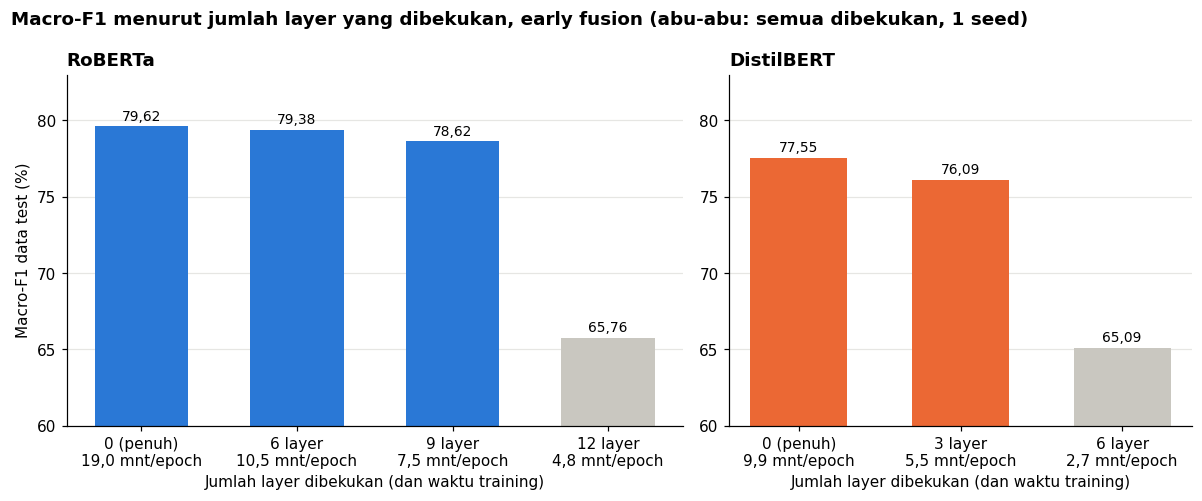

,H1,uji,pasangan,A menang,rata-rata A,rata-rata B,selisih,CI 95% selisih,p Shapiro,p t-test,p Wilcoxon,keputusan (sebelum Holm)
1,RoBERTa penuh > RoBERTa 6 layer dibekukan,paired t-test,3,3/3,"79,62","79,38","0,24","-0,02 sampai 0,49",-,"0,028",-,tolak H0
2,RoBERTa penuh > RoBERTa 9 layer dibekukan,paired t-test,3,3/3,"79,62","78,62","1,00","0,81 sampai 1,18",-,"< 0,001",-,tolak H0
3,DistilBERT penuh > DistilBERT 3 layer dibekukan,paired t-test,3,3/3,"77,55","76,09","1,47","1,28 sampai 1,66",-,"< 0,001",-,tolak H0
4,Penuh > dibekukan sebagian (gabungan 3 setting),paired t-test + Wilcoxon,9,9/9,"78,93","78,03","0,90","0,48 sampai 1,32","0,186","< 0,001","0,002",tolak H0
5,RoBERTa 9 layer dibekukan > DistilBERT penuh,paired t-test,3,3/3,"78,62","77,55","1,07","1,01 sampai 1,13",-,"< 0,001",-,tolak H0


In [ ]:
layer_tbl = mean_std(pd.concat([test[test["group"] == "S2_layer"], main_t[main_t["input"] == "early"].assign(layer="semua")]),
                     ["model", "layer"])
g = beku.groupby(["model", "dibekukan"])
tabel = pd.DataFrame({m: [koma(a * 100) if pd.isna(b) else f"{koma(a * 100)} ± {koma(b * 100)}" for a, b in zip(g[m].mean(), g[m].std())]
                      for m in M}, index=g.size().ohhindex)
tabel["train_min_per_epoch"] = g["train_min_per_epoch"].mean().round(2)
tabel["jumlah_seed"] = g.size()
display(nomor(tabel.sort_index(level=["model", "dibekukan"], ascending=[False, True])))

f1_beku = beku.pivot_table(index=["model", "seed"], columns="dibekukan", values="macro_f1") * 100
rata = beku.groupby(["model", "dibekukan"]).agg(f1=("macro_f1", "mean"), menit=("train_min_per_epoch", "mean"))
rata["f1"] *= 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [4, 3]})
for ax, m in zip(axes, NAMA):
    d = rata.xs(m)
    label = [(f"{k} layer" if k else "0 (penuh)") + f"\n{koma(mn, 1)} mnt/epoch" for k, mn in zip(d.index, d["menit"])]
    warna = [WARNA[m]] * (len(d) - 1) + ["#c9c7c0"]                    # abu-abu = semua dibekukan, hanya 1 seed
    b = ax.bar(label, d["f1"], color=warna, width=0.6)
    for bb, v in zip(b, d["f1"]):
        ax.text(bb.get_x() + bb.get_width() / 2, v + 0.4, koma(v), ha="center", fontsize=9)
    rapikan(ax, (60, 83), "Macro-F1 data test (%)" if m == "roberta" else "")
    ax.set_title(NAMA[m], loc="left", fontweight="bold")
    ax.set_xlabel("Jumlah layer dibekukan (dan waktu training)")
fig.suptitle("Macro-F1 menurut jumlah layer yang dibekukan, early fusion (abu-abu: semua dibekukan, 1 seed)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan(fig, "fig_layer_dibekukan")
plt.show()

R, D = f1_beku.loc["roberta"], f1_beku.loc["distilbert"]
uji_layer = [uji_dua("RQ1", "RoBERTa penuh > RoBERTa 6 layer dibekukan", R[0], R[6]),
             uji_dua("RQ1", "RoBERTa penuh > RoBERTa 9 layer dibekukan", R[0], R[9]),
             uji_dua("RQ1", "DistilBERT penuh > DistilBERT 3 layer dibekukan", D[0], D[3]),
             uji_dua("RQ1", "Penuh > dibekukan sebagian (gabungan 3 setting)", pd.concat([R[0], R[0], D[0]]),
                     pd.concat([R[6], R[9], D[3]]), utama=True),
             uji_dua("RQ1", "RoBERTa 9 layer dibekukan > DistilBERT penuh", R[9].values, D[0].values)]
tampil_uji(uji_layer)

#### Insight
Makin banyak layer dibekukan, macro-F1 makin turun. Gabungan ketiga setting menang 9 dari 9 pasangan (p Wilcoxon 0,002, p Holm 0,002), jadi H0 ditolak. Asumsi normal terpenuhi (p Shapiro 0,186).

RoBERTa dengan 6 layer dibekukan hanya turun 0,24 poin (79,62 menjadi 79,38), padahal waktu training turun dari 19,03 ke 10,51 menit per epoch. Penurunan ini signifikan menurut t-test satu arah (p 0,028), dan batas bawah CI 95% satu arahnya 0,07, jadi tidak mencakup 0. CI 95% dua arah di tabel (-0,02 sampai 0,49) memang sedikit menyentuh 0, karena CI dua arah lebih lebar dari uji satu arah. McNemar di bagian 12 juga tidak menganggapnya nyata. Jadi penurunannya ada, tetapi sangat kecil. Dengan 9 layer dibekukan, RoBERTa turun 1,00 poin, tetapi masih 1,07 poin di atas DistilBERT penuh dan lebih cepat dilatih (7,49 dibanding 9,93 menit). DistilBERT turun 1,47 poin hanya dengan 3 layer dibekukan. Kalau semua layer dibekukan, kedua model jatuh ke sekitar 65.

Jawaban RQ1: ada bukti statistik bahwa jumlah layer yang dibekukan berpengaruh. RoBERTa masih aman dibekukan sampai 6 dari 12 layer.

## 9. Perbandingan seed: 42 vs 43 vs 44

Bagian ini untuk mengecek apakah hasil bergantung pada seed. Ujinya Friedman (blok: 6 konfigurasi utama).

- H0: ketiga seed sama. H1: minimal ada satu seed yang berbeda.

Di sini yang diharapkan justru gagal menolak H0, karena artinya hasilnya stabil.

seed,model,input,42,43,44,selisih tertinggi-terendah
1,roberta,comment,78.48,78.48,78.59,0.11
2,roberta,early,79.60,79.68,79.57,0.11
3,roberta,late,79.32,79.28,79.29,0.04
4,distilbert,comment,76.90,76.92,76.78,0.15
5,distilbert,early,77.60,77.61,77.45,0.16
6,distilbert,late,77.57,77.61,77.59,0.04


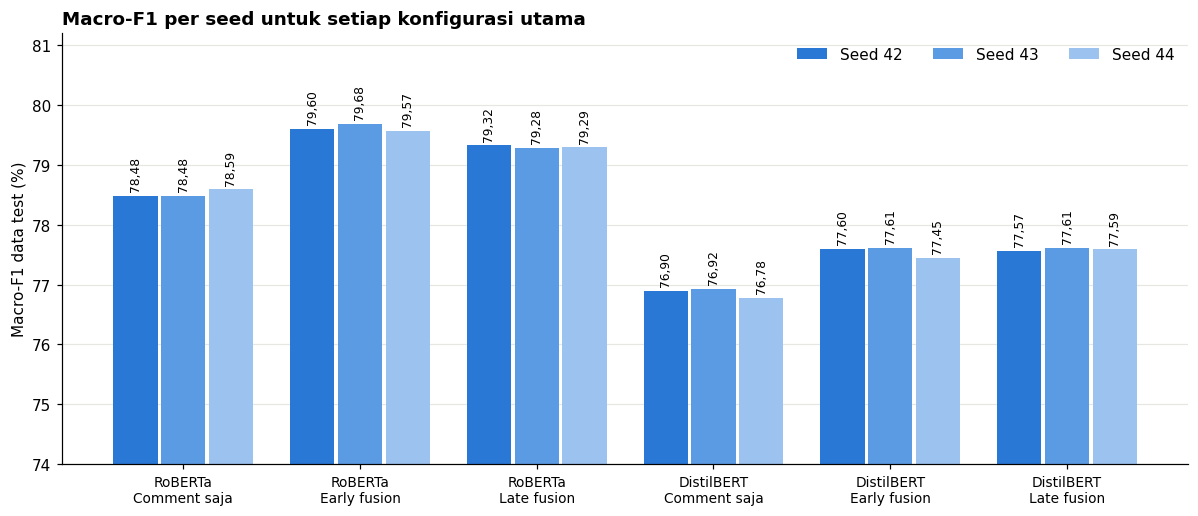

,H1,uji,pasangan,statistik,Kendall W,p Friedman,keputusan (sebelum Holm)
1,"Minimal satu seed berbeda (42, 43, 44)",Friedman,6,"2,33","0,19","0,311",gagal tolak H0


In [14]:
per_seed = main_t.pivot_table(index=["model", "input"], columns="seed", values="macro_f1").reindex(
    [(m, i) for m in NAMA for i in INPUT]) * 100
tabel = per_seed.copy()
tabel["selisih tertinggi-terendah"] = per_seed.max(axis=1) - per_seed.min(axis=1)
display(nomor(tabel.round(2)))

WARNA_SEED = {42: "#2a78d6", 43: "#5b9be3", 44: "#9cc2ef"}
fig, ax = plt.subplots(figsize=(11, 4.8))
x, w = np.arange(len(per_seed)), 0.27
for j, sd in enumerate(SEEDS):
    v = per_seed[sd].values
    label_batang(ax, ax.bar(x + (j - 1) * w, v, w - 0.02, color=WARNA_SEED[sd], label=f"Seed {sd}"), v, size=8, rot=90)
ax.set_xticks(x, [f"{NAMA[m]}\n{INPUT[i]}" for m, i in per_seed.index], fontsize=9)
rapikan(ax, (74, 81.2), "Macro-F1 data test (%)")
ax.set_title("Macro-F1 per seed untuk setiap konfigurasi utama", loc="left", fontweight="bold")
ax.legend(ncol=3, loc="upper right")
fig.tight_layout()
simpan(fig, "fig_perbandingan_seed")
plt.show()

tampil_uji([uji_friedman("Seed", "Minimal satu seed berbeda (42, 43, 44)", per_seed, utama=True)])

#### Insight
Tiga batang di tiap konfigurasi hampir sama tinggi. Selisih seed paling besar hanya 0,16 poin (early fusion DistilBERT, 77,61 dan 77,45). Friedman: p 0,311 dan Kendall's W 0,19, jadi H0 gagal ditolak dan tidak ada bukti bahwa seed berpengaruh.

Selisih karena seed (paling besar 0,16 poin) jauh lebih kecil dari selisih antarmodel (paling kecil 1,65 poin). Jadi perbedaan model dan input di bagian sebelumnya bukan karena kebetulan seed.

## 10. Perbandingan learning rate

Bagian ini untuk melihat pengaruh learning rate (1e-05, 2e-05, 3e-05, 5e-05) dari pencarian learning rate seed 42. Learning rate dipilih dengan validasi di notebook 06. Nilai test di sini hanya untuk melihat polanya, bukan untuk memilih ulang.

Ujinya Friedman (blok: 6 kombinasi model dan input), untuk validasi dan test.
- H0: keempat learning rate sama. H1: minimal ada satu yang berbeda.

Kolom `rata-rata peringkat`: 1 berarti paling baik.

Validasi


,model,input,1e-05,2e-05,3e-05,5e-05,LR terpilih (validasi)
1,roberta,comment,78.35,78.30,77.99,77.03,1e-05
2,roberta,early,79.55,79.74,79.36,78.39,2e-05
3,roberta,late,79.17,79.14,78.92,78.06,1e-05
4,distilbert,comment,76.67,76.70,76.72,76.37,3e-05
5,distilbert,early,77.56,77.52,77.43,76.87,1e-05
6,distilbert,late,77.62,77.58,77.48,76.95,1e-05


Test


,model,input,1e-05,2e-05,3e-05,5e-05,LR terpilih (validasi)
1,roberta,comment,78.48,78.44,78.10,77.08,1e-05
2,roberta,early,79.68,79.60,79.52,78.57,2e-05
3,roberta,late,79.32,79.32,79.00,78.19,1e-05
4,distilbert,comment,76.76,76.93,76.90,76.65,3e-05
5,distilbert,early,77.60,77.52,77.51,77.11,1e-05
6,distilbert,late,77.57,77.66,77.51,77.31,1e-05


Rata-rata peringkat (1 = terbaik)


,learning rate,validasi,test
1,1e-05,1.50,1.50
2,2e-05,1.83,1.67
3,3e-05,2.67,2.83
4,5e-05,4.00,4.00


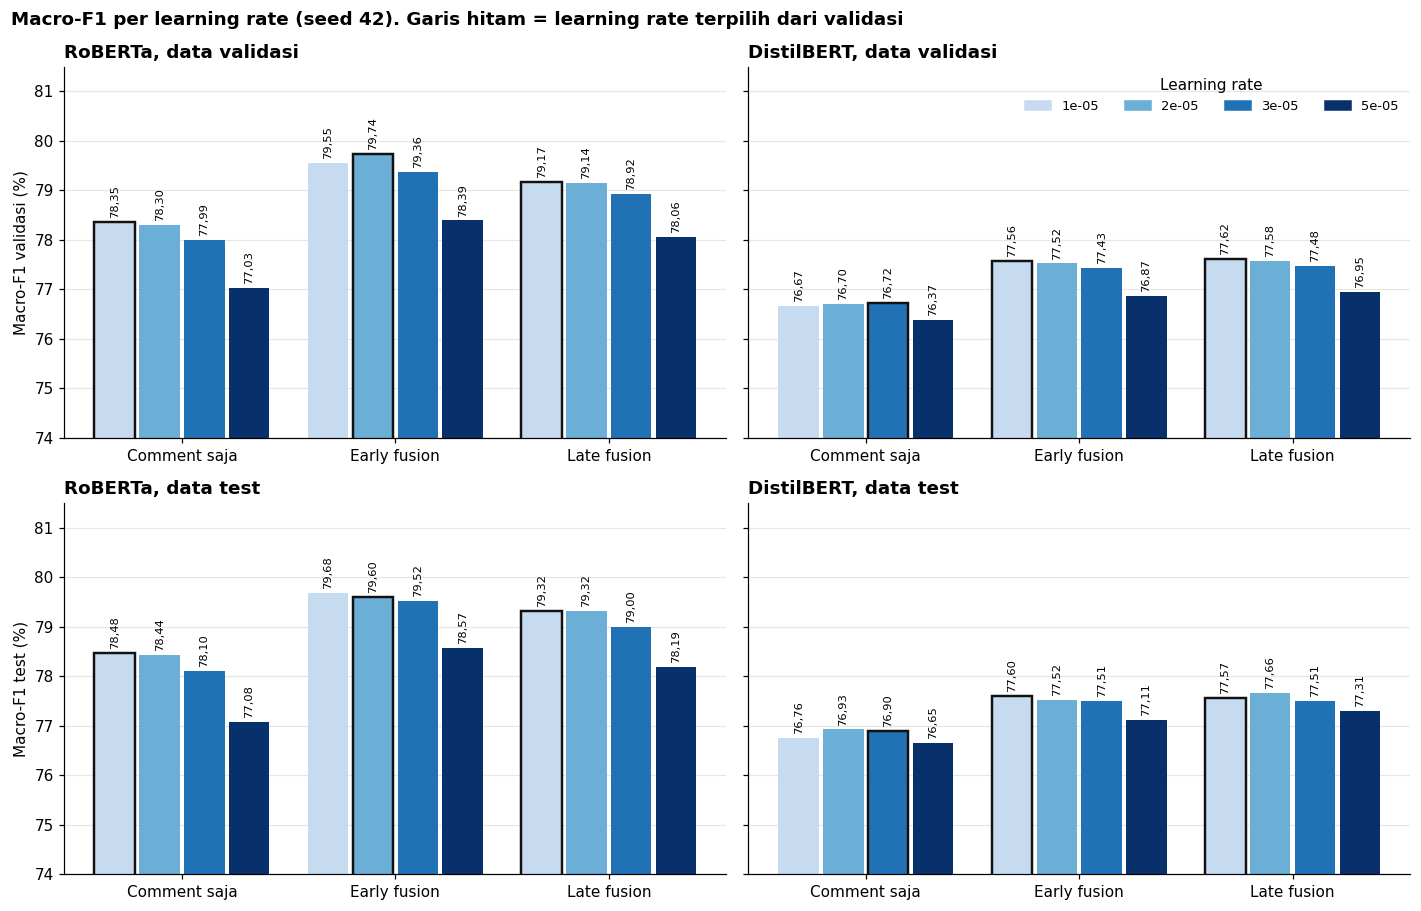

,H1,uji,pasangan,statistik,Kendall W,p Friedman,keputusan (sebelum Holm)
1,Minimal satu learning rate berbeda (validasi),Friedman,6,"13,40","0,74","0,004",tolak H0
2,Minimal satu learning rate berbeda (test),Friedman,6,"14,60","0,81","0,002",tolak H0


In [15]:
s1_run = runs[runs["putaran"].isin(["1", "2", "3"])]
skor_lr = []
for r in s1_run.itertuples():
    p = pd.read_parquet(FULL_DIR / "test_sealed" / f"{r.run_id}.parquet").set_index("raw_idx").sort_index()
    assert p.index.equals(ref.index)
    skor_lr.append({"run_id": r.run_id, "test_macro_f1": T.compute_metrics(y, p["prob_sarkas"].to_numpy())["macro_f1"]})
s1_run = s1_run.merge(pd.DataFrame(skor_lr), on="run_id")
urutan = [(m, i) for m in NAMA for i in INPUT]
lr_val = s1_run.pivot_table(index=["model", "input"], columns="lr", values="val_macro_f1").reindex(urutan) * 100
lr_test = s1_run.pivot_table(index=["model", "input"], columns="lr", values="test_macro_f1").reindex(urutan) * 100
for nama, tabel in [("Validasi", lr_val), ("Test", lr_test)]:
    t = tabel.copy()
    t.columns = [f"{c:.0e}" for c in t.columns]
    t["LR terpilih (validasi)"] = [f"{lr_val.loc[k].idxmax():.0e}" for k in tabel.index]
    print(nama)
    display(nomor(t.round(2)))
peringkat = pd.DataFrame({"validasi": lr_val.rank(axis=1, ascending=False).mean(), "test": lr_test.rank(axis=1, ascending=False).mean()})
peringkat.index = [f"{c:.0e}" for c in peringkat.index]
peringkat.index.name = "learning rate"
print("Rata-rata peringkat (1 = terbaik)")
display(nomor(peringkat.round(2)))

WARNA_LR = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8.4), sharey=True)
x, w = np.arange(3), 0.21
for r, (tabel, nama) in enumerate([(lr_val, "validasi"), (lr_test, "test")]):
    for c, m in enumerate(NAMA):
        ax = axes[r, c]
        for j, lr in enumerate(tabel.columns):
            v = [tabel.loc[(m, i), lr] for i in INPUT]
            b = ax.bar(x + (j - 1.5) * w, v, w - 0.02, color=WARNA_LR[j], label=f"{lr:.0e}",
                       edgecolor=["#111111" if lr_val.loc[(m, i)].idxmax() == lr else "none" for i in INPUT], linewidth=1.6)
            label_batang(ax, b, v, size=7.5, rot=90)
        ax.set_xticks(x, list(INPUT.values()))
        rapikan(ax, (74, 81.5), f"Macro-F1 {nama} (%)" if c == 0 else "")
        ax.set_title(f"{NAMA[m]}, data {nama}", loc="left", fontweight="bold")
axes[0, 1].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in WARNA_LR], [f"{lr:.0e}" for lr in lr_val.columns],
                  title="Learning rate", ncol=4, loc="upper right", fontsize=8.5)
fig.suptitle("Macro-F1 per learning rate (seed 42). Garis hitam = learning rate terpilih dari validasi", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan(fig, "fig_learning_rate")
plt.show()

tampil_uji([uji_friedman("Learning rate", "Minimal satu learning rate berbeda (validasi)", lr_val, utama=True),
            uji_friedman("Learning rate", "Minimal satu learning rate berbeda (test)", lr_test, utama=True)])

#### Insight
Ada bukti statistik bahwa learning rate berpengaruh, di validasi (p 0,004, Kendall's W 0,74) maupun di test (p 0,002, Kendall's W 0,81), juga setelah koreksi Holm. Polanya sama: 5e-05 selalu paling rendah (peringkat 4,00), dan 1e-05 paling baik secara rata-rata (peringkat 1,50).

RoBERTa lebih sensitif. Comment saja RoBERTa turun dari 78,35 (1e-05) ke 77,03 (5e-05) di validasi, sedangkan DistilBERT hampir datar dari 1e-05 sampai 3e-05 (76,67, 76,70, 76,72).

Learning rate terpilih tidak selalu yang tertinggi di test. Selisih terbesarnya 0,09 poin, yaitu late fusion DistilBERT (1e-05 terpilih dengan 77,57, padahal 2e-05 mendapat 77,66). Ini wajar karena pemilihan memang tidak boleh melihat data test.

## 11. Perbandingan biaya komputasi dan trade-off

Bagian ini untuk menjawab rumusan masalah kedua (efisiensi) dan ketiga (trade-off). Biaya yang dibandingkan: waktu training per epoch, latensi batch 1, latensi batch 32 (per data), dan memori GPU. Angkanya dari run final yang sama dengan skor test.

H1 semua uji di bagian ini: A lebih mahal dari B.
- RoBERTa vs DistilBERT (9 pasangan).
- Early fusion vs comment saja, yaitu biaya menambah parent (6 pasangan).
- Late fusion vs early fusion (6 pasangan).
- Model penuh vs dibekukan sebagian (3 pasangan).

,model,input,train_min_per_epoch,latency_bs1_ms,latency_bs32_ms,peak_mem_gb,params_total_m
1,roberta,comment,16.609,8.424,0.307,5.088,124.647
2,roberta,early,19.028,8.406,0.605,5.109,124.647
3,roberta,late,28.820,15.056,0.828,8.384,127.007
4,distilbert,comment,8.558,4.193,0.151,2.632,65.783
5,distilbert,early,9.934,4.234,0.316,2.639,65.783
6,distilbert,late,14.919,7.202,0.420,4.285,67.553


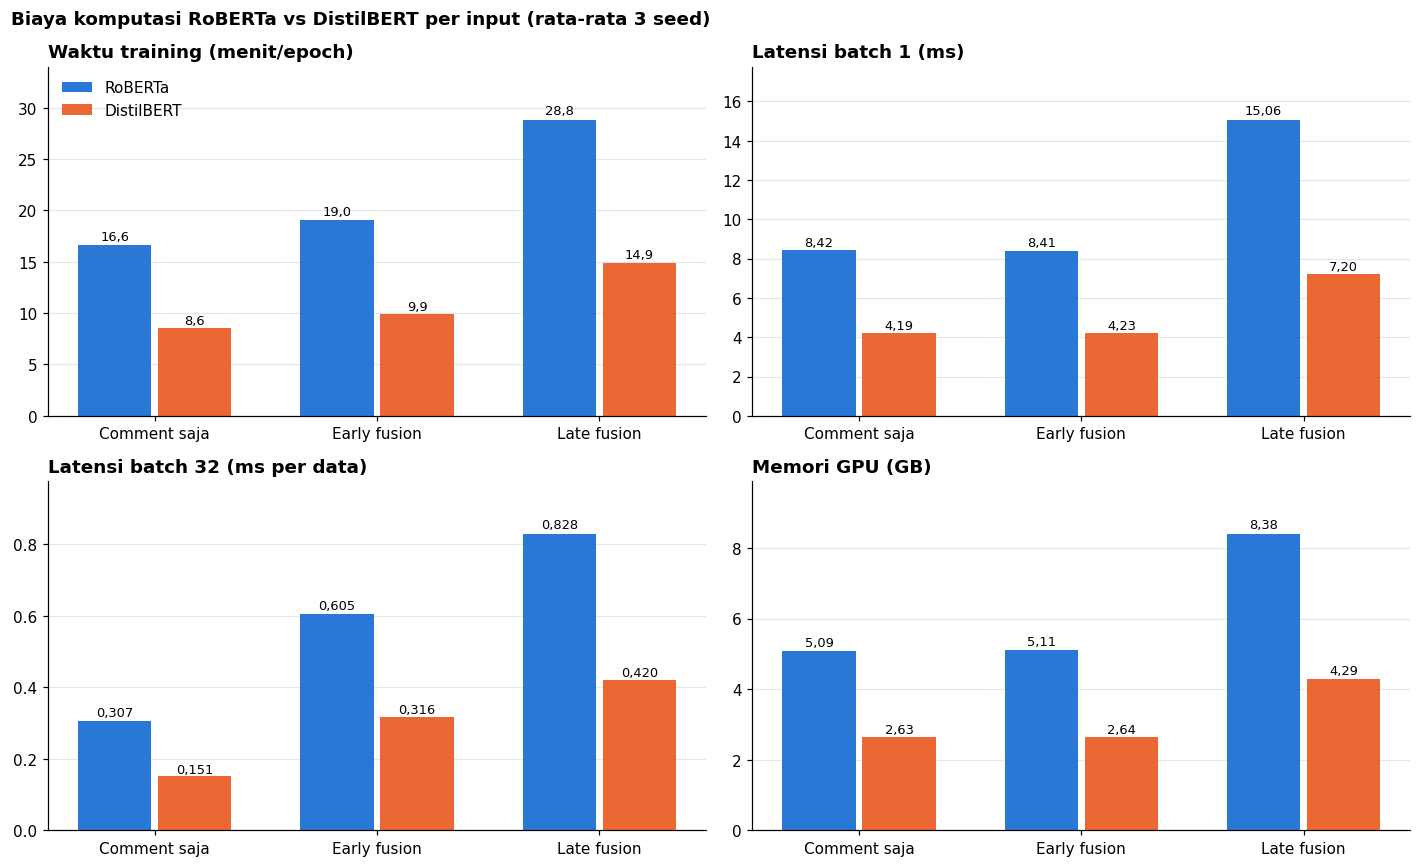

In [16]:
biaya = main_t.groupby(["model", "input"])[list(BIAYA) + ["params_total_m"]].mean().reindex(urutan)
display(nomor(biaya.round(3)))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
x, w = np.arange(3), 0.36
for ax, (kolom, judul) in zip(axes.flat, BIAYA.items()):
    d = 3 if kolom == "latency_bs32_ms" else (1 if kolom == "train_min_per_epoch" else 2)
    for j, m in enumerate(NAMA):
        v = [biaya.loc[(m, i), kolom] for i in INPUT]
        b = ax.bar(x + (j - 0.5) * w, v, w - 0.03, color=WARNA[m], label=NAMA[m])
        for bb, vv in zip(b, v):
            ax.text(bb.get_x() + bb.get_width() / 2, vv * 1.01, koma(vv, d), ha="center", va="bottom", fontsize=8.5)
    ax.set_xticks(x, list(INPUT.values()))
    ax.set_ylim(0, biaya[kolom].max() * 1.18)
    ax.set_title(judul, loc="left", fontweight="bold")
    ax.grid(axis="x", visible=False)
axes[0, 0].legend(loc="upper left")
fig.suptitle("Biaya komputasi RoBERTa vs DistilBERT per input (rata-rata 3 seed)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan(fig, "fig_biaya")
plt.show()

In [17]:
uji_biaya = []
for kolom, judul in BIAYA.items():
    nama = judul.split(" (")[0].lower()
    tb = main_t.pivot_table(index=["input", "seed"], columns="model", values=kolom)
    uji_biaya.append(uji_dua("Biaya", f"{nama}: RoBERTa > DistilBERT (gabungan 3 input)", tb["roberta"], tb["distilbert"],
                             utama=kolom in ["train_min_per_epoch", "latency_bs1_ms", "peak_mem_gb"]))
for kolom, judul in BIAYA.items():
    nama = judul.split(" (")[0].lower()
    ti = main_t.pivot_table(index=["model", "seed"], columns="input", values=kolom)
    uji_biaya.append(uji_dua("Biaya", f"{nama}: early fusion > comment saja (gabungan 2 model)", ti["early"], ti["comment"]))
    uji_biaya.append(uji_dua("Biaya", f"{nama}: late fusion > early fusion (gabungan 2 model)", ti["late"], ti["early"]))
for kolom in ["train_min_per_epoch", "peak_mem_gb", "latency_bs1_ms"]:
    nama = BIAYA[kolom].split(" (")[0].lower()
    tl = beku.pivot_table(index=["model", "seed"], columns="dibekukan", values=kolom)
    uji_biaya.append(uji_dua("Biaya", f"{nama}: RoBERTa penuh > RoBERTa 6 layer dibekukan", tl.loc["roberta"][0], tl.loc["roberta"][6]))
    uji_biaya.append(uji_dua("Biaya", f"{nama}: DistilBERT penuh > DistilBERT 3 layer dibekukan", tl.loc["distilbert"][0], tl.loc["distilbert"][3]))
tampil_uji(uji_biaya)

,H1,uji,pasangan,A menang,rata-rata A,rata-rata B,selisih,CI 95% selisih,p Shapiro,p t-test,p Wilcoxon,keputusan (sebelum Holm)
1,waktu training: RoBERTa > DistilBERT (gabungan 3 input),paired t-test + Wilcoxon,9,9/9,"21,49","11,14","10,35","8,27 sampai 12,43","0,006","< 0,001","0,002",tolak H0
2,latensi batch 1: RoBERTa > DistilBERT (gabungan 3 input),paired t-test + Wilcoxon,9,9/9,"10,63","5,21","5,42","4,01 sampai 6,82","< 0,001","< 0,001","0,002",tolak H0
3,latensi batch 32: RoBERTa > DistilBERT (gabungan 3 input),paired t-test + Wilcoxon,9,9/9,"0,58","0,30","0,28","0,20 sampai 0,37","0,228","< 0,001","0,002",tolak H0
4,memori gpu: RoBERTa > DistilBERT (gabungan 3 input),paired t-test + Wilcoxon,9,9/9,"6,19","3,19","3,01","2,38 sampai 3,64","< 0,001","< 0,001","0,002",tolak H0
5,waktu training: early fusion > comment saja (gabungan 2 model),paired t-test + Wilcoxon,6,6/6,"14,48","12,58","1,90","1,26 sampai 2,53","0,148","< 0,001","0,016",tolak H0
6,waktu training: late fusion > early fusion (gabungan 2 model),paired t-test + Wilcoxon,6,6/6,"21,87","14,48","7,39","4,61 sampai 10,16","0,015","< 0,001","0,016",tolak H0
7,latensi batch 1: early fusion > comment saja (gabungan 2 model),paired t-test + Wilcoxon,6,3/6,"6,32","6,31","0,01","-0,05 sampai 0,07","0,910","0,316","0,344",gagal tolak H0
8,latensi batch 1: late fusion > early fusion (gabungan 2 model),paired t-test + Wilcoxon,6,6/6,"11,13","6,32","4,81","2,69 sampai 6,93","0,017","0,001","0,016",tolak H0
9,latensi batch 32: early fusion > comment saja (gabungan 2 model),paired t-test + Wilcoxon,6,6/6,"0,46","0,23","0,23","0,15 sampai 0,31","0,191","< 0,001","0,016",tolak H0
10,latensi batch 32: late fusion > early fusion (gabungan 2 model),paired t-test + Wilcoxon,6,6/6,"0,62","0,46","0,16","0,10 sampai 0,23","0,027","< 0,001","0,016",tolak H0


#### Insight
RoBERTa lebih mahal di semua ukuran, menang 9 dari 9 pasangan (p Wilcoxon 0,002). Rata-ratanya: training 21,49 dibanding 11,14 menit per epoch, latensi batch 1 10,63 dibanding 5,21 ms, latensi batch 32 0,58 dibanding 0,30 ms, dan memori 6,19 dibanding 3,19 GB. Jawaban rumusan masalah kedua: ada bukti statistik bahwa RoBERTa sekitar 2 kali lebih berat dari DistilBERT.

Pada beberapa uji biaya, p Shapiro di bawah 0,05, jadi selisihnya tidak normal. Penyebabnya, biaya late fusion jauh lebih besar dari input lain. Untuk uji-uji ini Wilcoxon juga memberi p di bawah 0,05 dan semua pasangan searah, jadi kesimpulannya tetap.

Menambah parent lewat early fusion murah. Training bertambah 1,90 menit, latensi batch 1 tidak berubah (p 0,316), dan memori hanya +0,01 GB. Yang naik hanya latensi batch 32, sekitar dua kali (0,23 menjadi 0,46 ms per data), karena inputnya lebih panjang. Late fusion lebih mahal dari early fusion di semua ukuran: training +7,39 menit, latensi batch 1 +4,81 ms, dan memori +2,46 GB.

Pembekuan layer menghemat training dan memori (RoBERTa 19,03 ke 10,51 menit dan 5,11 ke 2,70 GB). Latensinya hanya turun 0,22 ms (RoBERTa) dan 0,14 ms (DistilBERT), dan setelah koreksi Holm tidak signifikan (p 0,079). Jadi pembekuan tidak membuat model lebih cepat menebak, karena semua layer tetap dijalankan.

Grafik berikut untuk merangkum trade-off. Semua nilai DistilBERT ditulis sebagai persen dari RoBERTa (RoBERTa = 100%). Batang hijau adalah macro-F1, batang abu-abu adalah biaya.

,input,Macro-F1,Waktu training,Latensi batch 1,Latensi batch 32,Memori GPU
1,comment,97.9,51.5,49.8,49.2,51.7
2,early,97.4,52.2,50.4,52.2,51.7
3,late,97.8,51.8,47.8,50.8,51.1


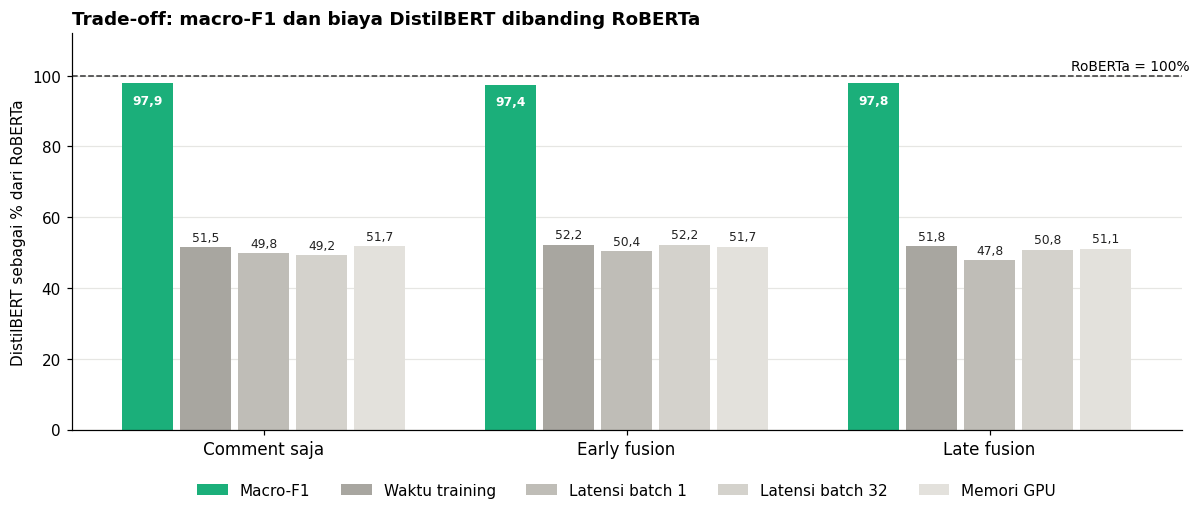

In [18]:
f1_rata = main_t.groupby(["model", "input"])["macro_f1"].mean()
persen = pd.DataFrame({"Macro-F1": f1_rata.loc["distilbert"] / f1_rata.loc["roberta"] * 100})
for kolom, judul in BIAYA.items():
    persen[judul.split(" (")[0]] = biaya.loc["distilbert", kolom] / biaya.loc["roberta", kolom] * 100
persen = persen.reindex(list(INPUT))
display(nomor(persen.round(1)))

WARNA_PERSEN = ["#1baf7a", "#a8a6a0", "#bfbdb7", "#d4d2cc", "#e3e1dc"]
fig, ax = plt.subplots(figsize=(11, 4.8))
x, w = np.arange(3), 0.16
for j, kolom in enumerate(persen.columns):
    v = persen[kolom].values
    batang = ax.bar(x + (j - 2) * w, v, w - 0.02, color=WARNA_PERSEN[j], label=kolom)
    for b, vv in zip(batang, v):
        ax.text(b.get_x() + b.get_width() / 2, vv - 3 if j == 0 else vv + 1, koma(vv, 1), ha="center",
                va="top" if j == 0 else "bottom", fontsize=8, color="white" if j == 0 else "#222222",
                fontweight="bold" if j == 0 else "normal")
ax.axhline(100, color="#333333", lw=1, ls="--")
ax.text(2.55, 101.5, "RoBERTa = 100%", ha="right", fontsize=9)
ax.set_xticks(x, list(INPUT.values()), fontsize=11)
rapikan(ax, (0, 112), "DistilBERT sebagai % dari RoBERTa")
ax.set_title("Trade-off: macro-F1 dan biaya DistilBERT dibanding RoBERTa", loc="left", fontweight="bold")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
simpan(fig, "fig_tradeoff")
plt.show()

#### Insight
DistilBERT mempertahankan 97,4 sampai 97,9% macro-F1 RoBERTa dengan biaya hanya 47,8 sampai 52,2%. Jadi dengan mengorbankan sekitar 2% performa, biaya bisa dihemat sekitar separuh.

Jawaban rumusan masalah ketiga: RoBERTa cocok kalau akurasi paling penting dan sumber daya cukup, misalnya analisis data secara offline. DistilBERT cocok kalau model harus cepat atau memori terbatas, misalnya untuk memproses comment terus-menerus.

## 12. Uji pendukung: McNemar per seed

Bagian ini untuk mengecek ulang perbandingan utama dari sisi lain. Kalau bagian 6 sampai 8 membandingkan skor per seed, McNemar membandingkan tebakan dua model pada 101.129 data test di seed yang sama. Hanya data yang tebakannya berbeda yang dihitung.

p dikoreksi dengan Holm (11 perbandingan per seed), dan rentang 95% dihitung dengan bootstrap 1.000 kali. Sebuah perbandingan dianggap nyata kalau p Holm di bawah 0,05 dan rentangnya tidak melewati 0, di ketiga seed.

In [19]:
def macro_f1_from_counts(tp, fp, fn, tn):
    return (2 * tp / (2 * tp + fp + fn) + 2 * tn / (2 * tn + fn + fp)) / 2


def compare(rid_a, rid_b, n_boot=1000, seed=0):
    """McNemar (A vs B pada data yang sama) + bootstrap berpasangan untuk selisih macro-F1 (A - B)."""
    pa, pb = pred[rid_a], pred[rid_b]
    ok_a, ok_b = pa == y, pb == y
    b, c = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    stat = (abs(b - c) - 1) ** 2 / (b + c)
    code = y * 4 + pa * 2 + pb
    rng = np.random.default_rng(seed)
    cnt = np.stack([np.bincount(code[rng.integers(0, len(y), len(y))], minlength=8) for _ in range(n_boot)]).astype(float)
    f_a = macro_f1_from_counts(cnt[:, 6] + cnt[:, 7], cnt[:, 2] + cnt[:, 3], cnt[:, 4] + cnt[:, 5], cnt[:, 0] + cnt[:, 1])
    f_b = macro_f1_from_counts(cnt[:, 5] + cnt[:, 7], cnt[:, 1] + cnt[:, 3], cnt[:, 4] + cnt[:, 6], cnt[:, 0] + cnt[:, 2])
    lo, hi = np.percentile(f_a - f_b, [2.5, 97.5]) * 100
    mf = test.set_index("run_id")["macro_f1"]
    return {"A_benar_B_salah": b, "A_salah_B_benar": c, "p_mcnemar": chi2.sf(stat, 1),
            "selisih_macro_f1": (mf[rid_a] - mf[rid_b]) * 100, "ci95_bawah": lo, "ci95_atas": hi}


def holm(p):
    p = np.asarray(p)
    order = np.argsort(p)
    adj = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    out = np.empty_like(adj)
    out[order] = adj
    return out


def nama_konfig(k):
    bagian = k.split("_")
    teks_ = f"{INPUT[bagian[0]]} {NAMA[bagian[1]]}"
    if len(bagian) == 3:
        teks_ += f" ({TOTAL_LAYER[bagian[1]] - int(bagian[2][1:])} layer dibekukan)"
    return teks_


rid = pd.concat([main_t.assign(key=main_t["input"] + "_" + main_t["model"]),
                 test[test["group"] == "S2_layer"].assign(key=lambda d: "early_" + d["model"] + "_L" + d["layer"])]
                ).set_index(["key", "seed"])["run_id"]
PAIRS = [("RoBERTa vs DistilBERT", f"{i}_roberta", f"{i}_distilbert") for i in ["comment", "early", "late"]]
PAIRS += [(f"{a} vs {b}", f"{a}_{m}", f"{b}_{m}") for a, b in [("early", "comment"), ("late", "comment"), ("late", "early")]
          for m in ["roberta", "distilbert"]]
PAIRS += [("RoBERTa 3 layer vs DistilBERT penuh", "early_roberta_L3", "early_distilbert"),
          ("RoBERTa 6 layer vs RoBERTa penuh", "early_roberta_L6", "early_roberta")]

sig = pd.DataFrame([{"seed": s, "perbandingan": name, "A": a, "B": b, **compare(rid[(a, s)], rid[(b, s)])}
                    for s in SEEDS for name, a, b in PAIRS])
sig["p_holm"] = sig.groupby("seed")["p_mcnemar"].transform(holm)
sig["signifikan"] = (sig["p_holm"] < 0.05) & ((sig["ci95_bawah"] > 0) | (sig["ci95_atas"] < 0))
sig_sum = sig.groupby(["perbandingan", "A", "B"], sort=False).agg(
    selisih_rata2=("selisih_macro_f1", "mean"), selisih_min=("selisih_macro_f1", "min"), selisih_max=("selisih_macro_f1", "max"),
    p_holm_terbesar=("p_holm", "max"), signifikan_di_semua_seed=("signifikan", "all"))

ci = sig.groupby(["perbandingan", "A", "B"], sort=False).agg(ci_bawah=("ci95_bawah", "min"), ci_atas=("ci95_atas", "max"))
uji = sig_sum.join(ci).reset_index()
mcnemar_tabel = pd.DataFrame({
    "A vs B": [f"{nama_konfig(a)} vs {nama_konfig(b)}" for a, b in zip(uji["A"], uji["B"])],
    "selisih macro-F1 A - B": uji["selisih_rata2"].map(koma),
    "rentang 95% (3 seed)": [f"{koma(lo)} sampai {koma(hi)}" for lo, hi in zip(uji["ci_bawah"], uji["ci_atas"])],
    "p Holm terbesar": uji["p_holm_terbesar"].map(lambda p: "< 0,001" if p < 0.001 else koma(p, 3)),
    "nyata di 3 seed": np.where(uji["signifikan_di_semua_seed"], "ya", "tidak"),
})
mcnemar_tabel.index = range(1, len(mcnemar_tabel) + 1)
with pd.option_context("display.max_colwidth", 90):
    display(mcnemar_tabel)

,A vs B,selisih macro-F1 A - B,rentang 95% (3 seed),p Holm terbesar,nyata di 3 seed
1,Comment saja RoBERTa vs Comment saja DistilBERT,"1,65","1,34 sampai 2,02","< 0,001",ya
2,Early fusion RoBERTa vs Early fusion DistilBERT,"2,07","1,78 sampai 2,33","< 0,001",ya
3,Late fusion RoBERTa vs Late fusion DistilBERT,"1,71","1,44 sampai 1,97","< 0,001",ya
4,Early fusion RoBERTa vs Comment saja RoBERTa,"1,10","0,78 sampai 1,42","< 0,001",ya
5,Early fusion DistilBERT vs Comment saja DistilBERT,"0,69","0,47 sampai 0,91","< 0,001",ya
6,Late fusion RoBERTa vs Comment saja RoBERTa,"0,78","0,53 sampai 1,02","< 0,001",ya
7,Late fusion DistilBERT vs Comment saja DistilBERT,"0,72","0,47 sampai 1,02","< 0,001",ya
8,Late fusion RoBERTa vs Early fusion RoBERTa,"-0,32","-0,59 sampai -0,08","0,015",ya
9,Late fusion DistilBERT vs Early fusion DistilBERT,"0,04","-0,21 sampai 0,32","0,966",tidak
10,Early fusion RoBERTa (9 layer dibekukan) vs Early fusion DistilBERT,"1,07","0,81 sampai 1,34","< 0,001",ya


#### Insight
9 dari 11 perbandingan nyata di ketiga seed, dan hasilnya sejalan dengan bagian 6 sampai 8: RoBERTa lebih baik dari DistilBERT, parent membantu di kedua model, early fusion lebih baik dari late fusion pada RoBERTa, dan RoBERTa 9 layer dibekukan lebih baik dari DistilBERT penuh.

Yang belum nyata: early vs late fusion pada DistilBERT (selisih 0,04, p 0,966) dan RoBERTa 6 layer dibekukan vs penuh (selisih -0,24, p 0,187). Yang kedua sejalan dengan bagian 8: penurunannya konsisten di 3 seed, tetapi terlalu kecil untuk dibedakan dari variasi data test.

## 13. Ringkasan jawaban rumusan masalah dan RQ

Bagian ini untuk merangkum uji utama dari bagian 6 sampai 11 dalam satu tabel.

- `p`: p t-test (uji 2 hal) atau p Friedman (uji 3 hal atau lebih).
- `p Holm`: p setelah dikoreksi di dalam kelompok pertanyaannya. Keputusan diambil dari kolom ini.
- `efek`: selisih dengan CI 95%, atau Kendall's W.

Tabel pertama menunjukkan uji yang keputusannya berubah setelah koreksi Holm. Semua 40 uji disimpan di `test_hypothesis.csv`.

In [23]:
TANYA = {"Model": "Proposal 1 (performa)", "Biaya": "Proposal 2 (efisiensi)", "RQ1": "RQ1 (layer dibekukan)",
         "RQ2": "RQ2 (parent comment)", "RQ2 dan RQ3": "RQ2 dan RQ3 (input)", "RQ3": "RQ3 (strategi fusion)",
         "Seed": "Kestabilan seed", "Learning rate": "Learning rate"}
# fungsi holm() sudah dibuat di bagian 12
semua_uji = pd.DataFrame(list(SEMUA_UJI.values()))
semua_uji["p"] = semua_uji["p t-test"].fillna(semua_uji["p Friedman"])
semua_uji["p Holm"] = semua_uji.groupby("bagian")["p"].transform(holm)
semua_uji["keputusan"] = np.where(semua_uji["p Holm"] < 0.05, "tolak H0", "gagal tolak H0")
semua_uji["efek"] = [f"W = {koma(w)}" if pd.notna(w) else f"{koma(s)} ({koma(lo)} sampai {koma(hi)})"
                     for w, s, lo, hi in zip(semua_uji.get("Kendall W", np.nan), semua_uji["selisih"],
                                             semua_uji["CI 95% bawah"], semua_uji["CI 95% atas"])]
berubah = semua_uji[(semua_uji["p"] < 0.05) != (semua_uji["p Holm"] < 0.05)]
print(f"{len(semua_uji)} uji. Keputusan yang berubah setelah koreksi Holm: {len(berubah)}")
display(nomor(berubah.set_index("H1")[["bagian", "p", "p Holm"]].round(4)))

ringkas = semua_uji[semua_uji["utama"]].assign(pertanyaan=lambda d: d["bagian"].map(TANYA))
ringkas = ringkas[["pertanyaan", "H1", "uji", "pasangan", "efek", "p", "p Holm", "keputusan"]]
for c in ["p", "p Holm"]:
    ringkas[c] = ringkas[c].map(lambda p: "< 0,001" if p < 0.001 else koma(p, 3))
ringkas.index = range(1, len(ringkas) + 1)
with pd.option_context("display.max_colwidth", 70):
    display(ringkas)

40 uji. Keputusan yang berubah setelah koreksi Holm: 2


,H1,bagian,p,p Holm
1,latensi batch 1: RoBERTa penuh > RoBERTa 6 lay...,Biaya,0.0264,0.0793
2,latensi batch 1: DistilBERT penuh > DistilBERT...,Biaya,0.0386,0.0793


,pertanyaan,H1,uji,pasangan,efek,p,p Holm,keputusan
1,Proposal 1 (performa),RoBERTa > DistilBERT (gabungan 3 input),paired t-test + Wilcoxon,9,"1,81 (1,65 sampai 1,97)","< 0,001","< 0,001",tolak H0
2,RQ2 dan RQ3 (input),"Minimal satu input berbeda (comment, early, late)",Friedman,6,"W = 0,78","0,009","0,009",tolak H0
3,RQ2 (parent comment),Early fusion > comment saja (gabungan 2 model),paired t-test + Wilcoxon,6,"0,89 (0,64 sampai 1,14)","< 0,001","< 0,001",tolak H0
4,RQ2 (parent comment),Late fusion > comment saja (gabungan 2 model),paired t-test + Wilcoxon,6,"0,75 (0,67 sampai 0,83)","< 0,001","< 0,001",tolak H0
5,RQ3 (strategi fusion),RoBERTa: early fusion > late fusion,paired t-test,3,"0,32 (0,15 sampai 0,49)","0,008","0,023",tolak H0
6,RQ3 (strategi fusion),DistilBERT: early fusion > late fusion,paired t-test,3,"-0,04 (-0,26 sampai 0,19)","0,725","0,725",gagal tolak H0
7,RQ3 (strategi fusion),Early fusion > late fusion (gabungan 2 model),paired t-test + Wilcoxon,6,"0,14 (-0,08 sampai 0,36)","0,079","0,158",gagal tolak H0
8,RQ1 (layer dibekukan),Penuh > dibekukan sebagian (gabungan 3 setting),paired t-test + Wilcoxon,9,"0,90 (0,48 sampai 1,32)","< 0,001","0,002",tolak H0
9,Kestabilan seed,"Minimal satu seed berbeda (42, 43, 44)",Friedman,6,"W = 0,19","0,311","0,311",gagal tolak H0
10,Learning rate,Minimal satu learning rate berbeda (validasi),Friedman,6,"W = 0,74","0,004","0,004",tolak H0


#### Insight
Dari 40 uji, hanya 2 yang keputusannya berubah setelah koreksi Holm, yaitu penurunan latensi karena pembekuan layer (p 0,026 dan 0,039 menjadi 0,079). Keduanya bukan uji utama.

Dari 14 uji utama, 11 menolak H0 dan 3 gagal menolak H0. Yang gagal menolak H0: early vs late fusion pada DistilBERT, early vs late fusion gabungan, dan perbedaan antarseed. Artinya keunggulan early fusion hanya didukung bukti pada RoBERTa, dan hasilnya stabil terhadap seed.

Hasil ini mendukung jawaban RQ, tetapi hanya berlaku pada dataset, pengaturan, dan tiga seed yang dipakai.

## 14. Menyimpan hasil

Bagian ini untuk menyimpan semua tabel hasil ke `data/test_results_rtx5070ti/` supaya bisa dipakai di paper tanpa menjalankan ulang notebook.

In [24]:
simpanan = {
    "test_metrics.csv": (test, False), "test_summary_main.csv": (summary, True), "test_layer.csv": (layer_tbl, True),
    "test_significance.csv": (sig, False), "test_significance_summary.csv": (sig_sum, True),
    "test_hypothesis.csv": (semua_uji.drop(columns="p"), False), "test_lr.csv": (s1_run, False),
    "test_parent_subgroup.csv": (parent_ringkas, True), "test_efficiency.csv": (biaya, True),
}
for nama, (df, pakai_index) in simpanan.items():
    df.to_csv(RESULT_DIR / nama, index=pakai_index)
print("Tersimpan:", ", ".join(simpanan))

Tersimpan: test_metrics.csv, test_summary_main.csv, test_layer.csv, test_significance.csv, test_significance_summary.csv, test_hypothesis.csv, test_lr.csv, test_parent_subgroup.csv, test_efficiency.csv


## 15. Kesimpulan

Bagian ini untuk menjawab rumusan masalah dan RQ secara singkat. Keputusan memakai p Holm, dan "ada bukti statistik" berarti hasil uji mendukung, bukan bukti mutlak.

Rumusan masalah:
1. Performa: ada bukti statistik bahwa RoBERTa lebih baik dari DistilBERT, selisih 1,65 sampai 2,07 poin macro-F1 (gabungan 1,81, CI 95% 1,65 sampai 1,97). Hasil terbaik early fusion RoBERTa: accuracy 79,63 ± 0,05, precision 79,37 ± 1,31, recall 79,32 ± 2,22, F1 79,32 ± 0,48, macro-F1 79,62 ± 0,06.
2. Efisiensi: RoBERTa (124,6 juta parameter) sekitar 2 kali lebih berat dari DistilBERT (65,8 juta) di waktu training, latensi, dan memori (p Wilcoxon 0,002).
3. Trade-off: DistilBERT mempertahankan 97,4 sampai 97,9% macro-F1 RoBERTa dengan biaya 47,8 sampai 52,2%. RoBERTa untuk akurasi, DistilBERT untuk kecepatan dan hemat memori.

RQ:
1. RQ1: ada bukti statistik bahwa jumlah layer yang dibekukan berpengaruh (p Wilcoxon 0,002). RoBERTa aman sampai 6 dari 12 layer (turun 0,24 poin, training hampir separuh). Semua layer dibekukan membuat macro-F1 jatuh ke sekitar 65. Pembekuan hanya menghemat training, bukan latensi.
2. RQ2: ada bukti statistik bahwa parent comment berpengaruh. Early fusion +1,10 dan +0,69, late fusion +0,78 dan +0,72 (p Wilcoxon gabungan 0,016). Paling membantu saat comment ambigu, misalnya saat model ragu (+8,18 pada RoBERTa).
3. RQ3: early fusion. Lebih baik dari late fusion pada RoBERTa (+0,32, p Holm 0,023), tidak berbeda pada DistilBERT (p 0,725), dan jauh lebih murah (late fusion sekitar 1,5 kali training dan 1,75 kali latensi).

Tambahan: seed tidak berpengaruh (p 0,311), sedangkan learning rate berpengaruh (p 0,004), terutama pada RoBERTa di 5e-05.

Keterbatasan: training maksimal 3 epoch padahal sebagian besar model masih terbaik di epoch 3, model yang semua layernya dibekukan hanya 1 seed, learning rate model yang dibekukan sebagian mengikuti training penuh, uji per konfigurasi hanya punya 3 pasangan seed, dan test set resmi SARC tidak dipakai karena hanya berisi ID tanpa teks.